In [1]:
import os

INPUT_DIR = "/kaggle/input"
WORKING_DIR = "/kaggle/working"

# Image extensions to ignore when listing files
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif",
    ".webp", ".tif", ".tiff"
}

def show_structure(base_dir):
    print("=" * 80)
    print(f"STRUCTURE: {base_dir}")
    print("=" * 80)

    for root, dirs, files in os.walk(base_dir):
        # Sort for clean output
        dirs.sort()
        files.sort()

        level = root.replace(base_dir, "").count(os.sep)
        indent = "    " * level

        folder_name = os.path.basename(root) or base_dir
        print(f"{indent}📁 {folder_name}/")

        # Show only non-image files
        other_files = [
            f for f in files
            if os.path.splitext(f)[1].lower() not in IMAGE_EXTENSIONS
        ]

        # Count images instead of printing thousands of them
        image_count = sum(
            1 for f in files
            if os.path.splitext(f)[1].lower() in IMAGE_EXTENSIONS
        )

        if image_count > 0:
            print(f"{indent}    🖼️ [{image_count} image files]")

        for file in other_files:
            print(f"{indent}    📄 {file}")


# Input structure
show_structure(INPUT_DIR)

print("\n")

# Working structure
show_structure(WORKING_DIR)

STRUCTURE: /kaggle/input
📁 input/
    📁 datasets/
        📁 ayush1220/
            📁 cifar10/
                📁 cifar10/
                    📁 test/
                        📁 airplane/
                            🖼️ [1000 image files]
                        📁 automobile/
                            🖼️ [1000 image files]
                        📁 bird/
                            🖼️ [1000 image files]
                        📁 cat/
                            🖼️ [1000 image files]
                        📁 deer/
                            🖼️ [1000 image files]
                        📁 dog/
                            🖼️ [1000 image files]
                        📁 frog/
                            🖼️ [1000 image files]
                        📁 horse/
                            🖼️ [1000 image files]
                        📁 ship/
                            🖼️ [1000 image files]
                        📁 truck/
                            🖼️ [1000 image files]
                    📁

CORRECTED GRAD-CAM TEST
Device: cuda
✓ ResNet-50 loaded

CHECKING RESNET FEATURE MAP SIZES

Feature map sizes:
layer2[-1]: (1, 512, 4, 4)
layer3[-1]: (1, 1024, 2, 2)
layer4[-1]: (1, 2048, 1, 1)

Selected Grad-CAM target:
model.layer3[-1]

CIFAR-10-C
Shape: (50000, 32, 32, 3)
Labels: (50000,)
Selected CIFAR-10-C index: 3
CIFAR-10-C label: airplane

PAIRING CHECK
Clean folder image: /kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0001.png
CIFAR-10-C image index: 3

NOTE: Class matching confirmed.

GENERATING GRAD-CAM

Clean prediction:
cat | confidence: 0.1866

Corrupted prediction:
cat | confidence: 0.1669

Grad-CAM shapes:
Clean: (2, 2)
Corrupted: (2, 2)

INITIAL EXPLANATION INSTABILITY
Mean absolute Grad-CAM difference: 0.03848


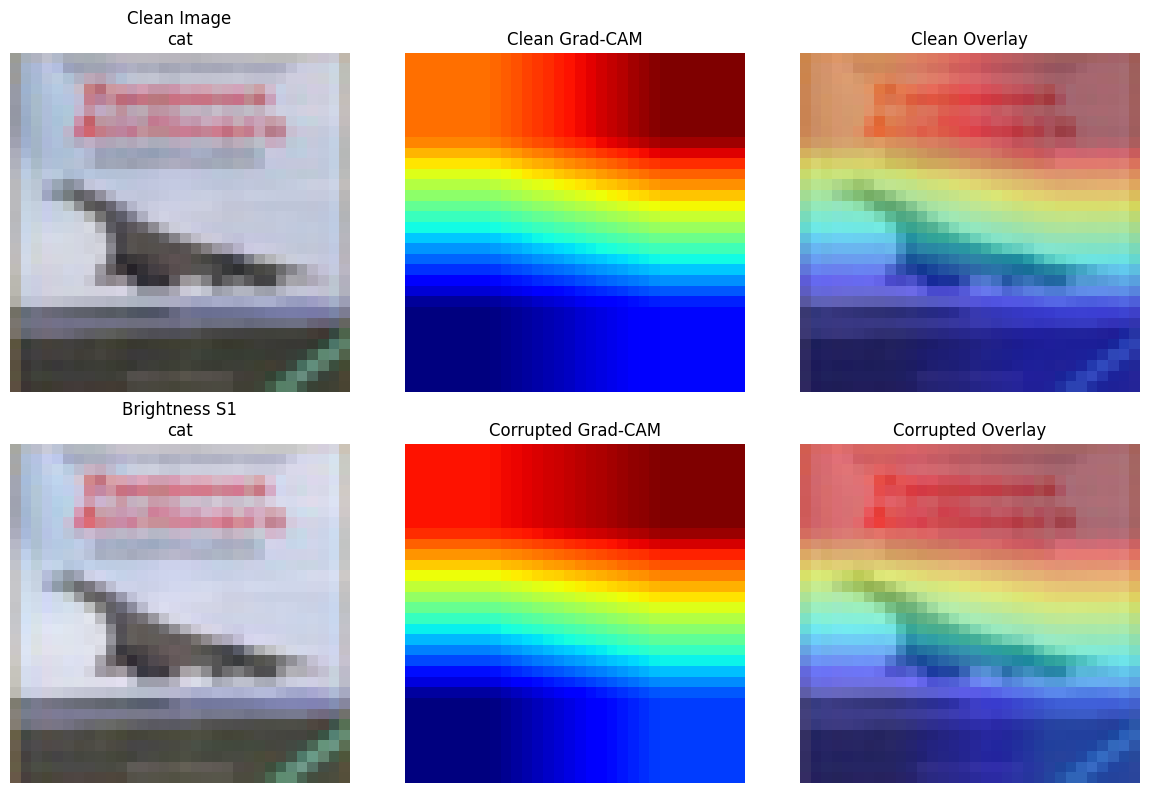


✓ Grad-CAM test finished.


In [2]:
# ============================================================
# CORRECTED GRAD-CAM TEST FOR CIFAR-10 / CIFAR-10-C
# ============================================================

import os
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

MODEL_PATH = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "pretrained-model/resnet50_cifar10.pth"
)

CLEAN_DIR = (
    "/kaggle/input/datasets/ayush1220/"
    "cifar10/cifar10/test"
)

CIFAR10C_DIR = (
    "/kaggle/input/datasets/harshadakhatu/"
    "cifar-10-c/CIFAR-10-C"
)

classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("CORRECTED GRAD-CAM TEST")
print("=" * 70)

print("Device:", device)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = torchvision.models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

# Handle cases where checkpoint is wrapped in a 'model_state_dict' key or direct
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

# Remove module. prefix if trained with DataParallel
state_dict = {
    k.replace("module.", ""): v
    for k, v in state_dict.items()
}

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("✓ ResNet-50 loaded")


# ------------------------------------------------------------
# CHECK FEATURE MAP SIZES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING RESNET FEATURE MAP SIZES")
print("=" * 70)

feature_shapes = {}
hooks = []

def make_hook(name):
    def hook(module, input, output):
        feature_shapes[name] = tuple(output.shape)
    return hook

hooks.append(
    model.layer2[-1].register_forward_hook(
        make_hook("layer2[-1]")
    )
)

hooks.append(
    model.layer3[-1].register_forward_hook(
        make_hook("layer3[-1]")
    )
)

hooks.append(
    model.layer4[-1].register_forward_hook(
        make_hook("layer4[-1]")
    )
)


# ------------------------------------------------------------
# LOAD ONE CIFAR-10 IMAGE
# ------------------------------------------------------------

clean_class = "airplane"

class_dir = os.path.join(
    CLEAN_DIR,
    clean_class
)

image_files = sorted([
    f for f in os.listdir(class_dir)
    if f.lower().endswith(
        (".png", ".jpg", ".jpeg", ".bmp")
    )
])

clean_image_path = os.path.join(
    class_dir,
    image_files[0]
)

clean_pil = Image.open(
    clean_image_path
).convert("RGB")

clean_np = np.array(clean_pil)


# ------------------------------------------------------------
# NORMALIZATION
# ------------------------------------------------------------

mean = [0.4914, 0.4822, 0.4465]
std = [0.2470, 0.2435, 0.2616]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

clean_tensor = transform(
    clean_pil
).unsqueeze(0).to(device)


# Forward pass only to inspect shapes
with torch.no_grad():
    test_output = model(clean_tensor)

# Explicitly remove size-checking hooks
for h in hooks:
    h.remove()

print("\nFeature map sizes:")
for name, shape in feature_shapes.items():
    print(f"{name}: {shape}")


# ------------------------------------------------------------
# CHOOSE SPATIAL TARGET LAYER
# ------------------------------------------------------------

# For CIFAR-10 32x32 images, layer3 retains more resolution (4x4 vs 2x2)
TARGET_LAYER = model.layer3[-1]

print("\nSelected Grad-CAM target:")
print("model.layer3[-1]")


# ------------------------------------------------------------
# LOAD CIFAR-10-C
# ------------------------------------------------------------

corruption = "brightness"
severity = 1

corruption_path = os.path.join(
    CIFAR10C_DIR,
    corruption + ".npy"
)

labels_path = os.path.join(
    CIFAR10C_DIR,
    "labels.npy"
)

cifar_c = np.load(
    corruption_path
)

labels = np.load(
    labels_path
)

print("\n" + "=" * 70)
print("CIFAR-10-C")
print("=" * 70)

print("Shape:", cifar_c.shape)
print("Labels:", labels.shape)


# ------------------------------------------------------------
# FIND A CIFAR-10-C SAMPLE MATCHING AIRPLANE
# ------------------------------------------------------------

severity_start = (severity - 1) * 10000
severity_end = severity * 10000

severity_labels = labels[
    severity_start:severity_end
]

target_class_index = classes.index(
    clean_class
)

matching_indices = np.where(
    severity_labels == target_class_index
)[0]

if len(matching_indices) == 0:
    raise RuntimeError(
        "Could not find matching CIFAR-10-C class."
    )

cifar_local_index = matching_indices[0]

cifar_global_index = (
    severity_start +
    cifar_local_index
)

corrupted_image = cifar_c[
    cifar_global_index
]

print(
    "Selected CIFAR-10-C index:",
    cifar_global_index
)

print(
    "CIFAR-10-C label:",
    classes[
        int(labels[cifar_global_index])
    ]
)


# ------------------------------------------------------------
# PAIRING CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PAIRING CHECK")
print("=" * 70)

print(
    "Clean folder image:",
    clean_image_path
)

print(
    "CIFAR-10-C image index:",
    cifar_global_index
)

print(
    "\nNOTE: Class matching confirmed."
)


# ------------------------------------------------------------
# PREPARE CORRUPTED IMAGE
# ------------------------------------------------------------

corrupted_pil = Image.fromarray(
    corrupted_image.astype(np.uint8)
)

corrupted_tensor = transform(
    corrupted_pil
).unsqueeze(0).to(device)


# ------------------------------------------------------------
# GRAD-CAM IMPLEMENTATION (CORRECTED)
# ------------------------------------------------------------

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = (
            target_layer.register_forward_hook(
                self.forward_hook_fn
            )
        )

        self.backward_hook = (
            target_layer.register_full_backward_hook(
                self.backward_hook_fn
            )
        )

    def forward_hook_fn(
        self,
        module,
        input,
        output
    ):
        self.activations = output.detach()

    def backward_hook_fn(
        self,
        module,
        grad_input,
        grad_output
    ):
        self.gradients = grad_output[0].detach()

    def generate(self, image):

        self.model.zero_grad()

        output = self.model(image)

        predicted_class = output.argmax(
            dim=1
        ).item()

        score = output[
            0,
            predicted_class
        ]

        score.backward()

        activations = self.activations
        gradients = self.gradients

        # Global average pooling over spatial dimensions
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights *
            activations
        ).sum(dim=1)

        cam = torch.relu(cam)

        cam = cam.squeeze(0).cpu().numpy()

        # Min-Max Normalization
        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)

        return (
            cam,
            predicted_class,
            output.detach()
        )

    def close(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


# ------------------------------------------------------------
# GENERATE CAMS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GENERATING GRAD-CAM")
print("=" * 70)

gradcam = GradCAM(
    model,
    TARGET_LAYER
)

clean_cam, clean_pred, clean_output = (
    gradcam.generate(clean_tensor)
)

corrupted_cam, corrupted_pred, corrupted_output = (
    gradcam.generate(corrupted_tensor)
)

gradcam.close()


# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

clean_probs = torch.softmax(
    clean_output,
    dim=1
)[0]

corrupted_probs = torch.softmax(
    corrupted_output,
    dim=1
)[0]

print("\nClean prediction:")
print(
    classes[clean_pred],
    "| confidence:",
    round(
        clean_probs[clean_pred].item(),
        4
    )
)

print("\nCorrupted prediction:")
print(
    classes[corrupted_pred],
    "| confidence:",
    round(
        corrupted_probs[corrupted_pred].item(),
        4
    )
)

print("\nGrad-CAM shapes:")
print("Clean:", clean_cam.shape)
print("Corrupted:", corrupted_cam.shape)


# ------------------------------------------------------------
# RESIZE CAM TO 32 x 32
# ------------------------------------------------------------

clean_cam_32 = np.array(
    Image.fromarray(
        (clean_cam * 255).astype(np.uint8)
    ).resize(
        (32, 32),
        Image.Resampling.BILINEAR
    )
) / 255.0

corrupted_cam_32 = np.array(
    Image.fromarray(
        (corrupted_cam * 255).astype(np.uint8)
    ).resize(
        (32, 32),
        Image.Resampling.BILINEAR
    )
) / 255.0


# ------------------------------------------------------------
# EXPLANATION INSTABILITY
# ------------------------------------------------------------

explanation_instability = np.mean(
    np.abs(
        clean_cam_32 -
        corrupted_cam_32
    )
)

print("\n" + "=" * 70)
print("INITIAL EXPLANATION INSTABILITY")
print("=" * 70)

print(
    "Mean absolute Grad-CAM difference:",
    round(
        float(explanation_instability),
        6
    )
)


# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(clean_np)
plt.title(
    f"Clean Image\n{classes[clean_pred]}"
)
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(clean_cam_32, cmap="jet")
plt.title("Clean Grad-CAM")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(clean_np)
plt.imshow(
    clean_cam_32,
    cmap="jet",
    alpha=0.5
)
plt.title("Clean Overlay")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(corrupted_image)
plt.title(
    f"Brightness S1\n{classes[corrupted_pred]}"
)
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(corrupted_cam_32, cmap="jet")
plt.title("Corrupted Grad-CAM")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(corrupted_image)
plt.imshow(
    corrupted_cam_32,
    cmap="jet",
    alpha=0.5
)
plt.title("Corrupted Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("\n✓ Grad-CAM test finished.")

CIFAR-10-C brightness: (50000, 32, 32, 3)

Loading clean PNG images...
Clean images: (10000, 32, 32, 3)

Creating clean fingerprints...
Clean fingerprint shape: (10000, 8, 8, 3)

Creating CIFAR-10-C fingerprints...
Corrupted fingerprint shape: (10000, 8, 8, 3)

MATCHING CLEAN IMAGES TO CIFAR-10-C

airplane: 1000 clean / 1000 CIFAR-C

automobile: 1000 clean / 1000 CIFAR-C

bird: 1000 clean / 1000 CIFAR-C

cat: 1000 clean / 1000 CIFAR-C

deer: 1000 clean / 1000 CIFAR-C

dog: 1000 clean / 1000 CIFAR-C

frog: 1000 clean / 1000 CIFAR-C

horse: 1000 clean / 1000 CIFAR-C

ship: 1000 clean / 1000 CIFAR-C

truck: 1000 clean / 1000 CIFAR-C

MATCHING RESULTS
Successfully matched: 10000 / 10000
Mean matching error: 0.00054991496
Maximum matching error: 0.018599689
Median matching error: 0.0003643632

Unique clean images used: 10000
✓ PERFECT ONE-TO-ONE MAPPING

Mapping saved to: /kaggle/working/cifar10c_to_clean_png_mapping.npy

FIRST 20 MATCHES
CIFAR-C    0 | Clean PNG index 3000 | /kaggle/input/

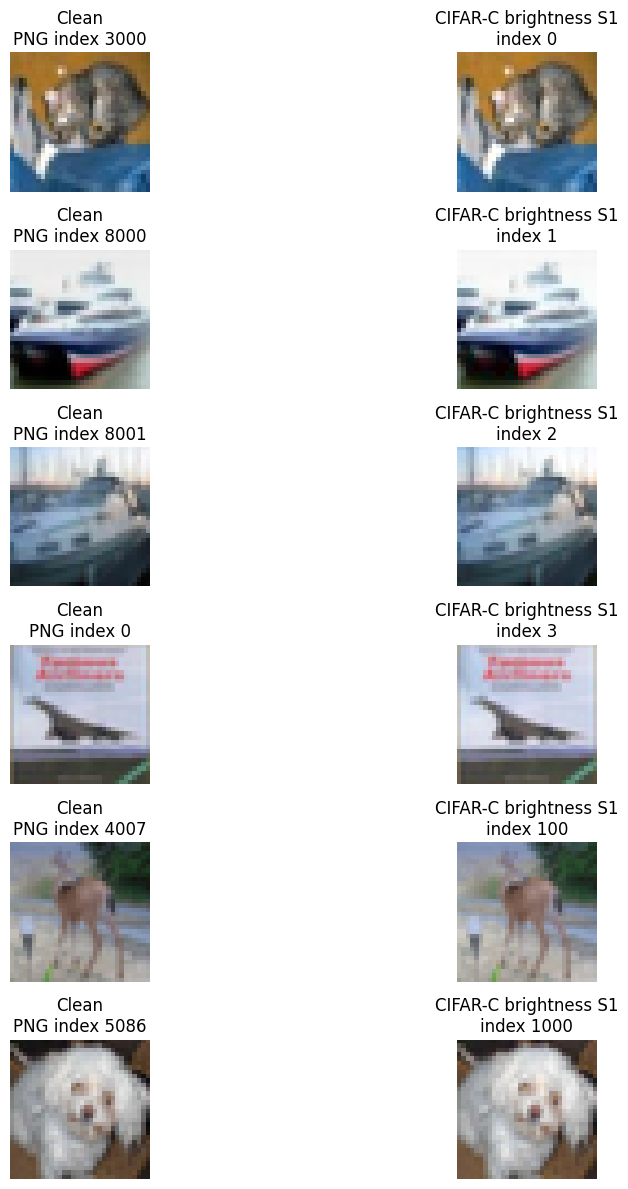


✓ Mapping test completed.


In [3]:
# ============================================================
# RECOVER EXACT CLEAN ↔ CIFAR-10-C ORDER
# Using brightness corruption + image fingerprints
# ============================================================

import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

CLEAN_DIR = (
    "/kaggle/input/datasets/ayush1220/"
    "cifar10/cifar10/test"
)

CIFAR10C_DIR = (
    "/kaggle/input/datasets/harshadakhatu/"
    "cifar-10-c/CIFAR-10-C"
)

classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

# ------------------------------------------------------------
# LOAD BRIGHTNESS CORRUPTION
# ------------------------------------------------------------

brightness = np.load(
    os.path.join(
        CIFAR10C_DIR,
        "brightness.npy"
    )
)

print("CIFAR-10-C brightness:", brightness.shape)


# ------------------------------------------------------------
# LOAD ALL CLEAN PNGS
# ------------------------------------------------------------

print("\nLoading clean PNG images...")

clean_images = []
clean_paths = []
clean_labels = []

for class_idx, class_name in enumerate(classes):

    class_dir = os.path.join(
        CLEAN_DIR,
        class_name
    )

    files = sorted([
        f for f in os.listdir(class_dir)
        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        )
    ])

    for f in files:

        path = os.path.join(
            class_dir,
            f
        )

        img = np.array(
            Image.open(path).convert("RGB")
        )

        clean_images.append(img)
        clean_paths.append(path)
        clean_labels.append(class_idx)

clean_images = np.stack(clean_images)
clean_labels = np.array(clean_labels)

print(
    "Clean images:",
    clean_images.shape
)


# ------------------------------------------------------------
# CREATE LOW-RESOLUTION FINGERPRINTS
# ------------------------------------------------------------

def make_fingerprint(images):

    # Convert to float
    images = images.astype(np.float32)

    # Downsample 32x32 → 8x8
    # Simple 4x4 block average
    fingerprints = images.reshape(
        images.shape[0],
        8, 4,
        8, 4,
        3
    ).mean(axis=(2, 4))

    # Normalize each image
    mean = fingerprints.mean(
        axis=(1, 2),
        keepdims=True
    )

    std = fingerprints.std(
        axis=(1, 2),
        keepdims=True
    ) + 1e-6

    fingerprints = (
        fingerprints - mean
    ) / std

    return fingerprints


print("\nCreating clean fingerprints...")

clean_fp = make_fingerprint(
    clean_images
)

print(
    "Clean fingerprint shape:",
    clean_fp.shape
)


# ------------------------------------------------------------
# BUILD FINGERPRINTS FOR CIFAR-10-C
# ------------------------------------------------------------

print("\nCreating CIFAR-10-C fingerprints...")

# Only severity 1
corrupted_s1 = brightness[:10000]

corrupted_fp = make_fingerprint(
    corrupted_s1
)

print(
    "Corrupted fingerprint shape:",
    corrupted_fp.shape
)


# ------------------------------------------------------------
# MATCH BY CLASS FIRST
# ------------------------------------------------------------

labels = np.load(
    os.path.join(
        CIFAR10C_DIR,
        "labels.npy"
    )
)

cifar_labels = labels[:10000]


# ------------------------------------------------------------
# MATCH IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MATCHING CLEAN IMAGES TO CIFAR-10-C")
print("=" * 70)

# We cannot compare all 10,000 × 10,000 pairs at once.
# Match separately inside each class.

mapping = np.full(
    10000,
    -1,
    dtype=np.int32
)

match_errors = np.full(
    10000,
    np.inf,
    dtype=np.float32
)

for class_idx, class_name in enumerate(classes):

    clean_idx = np.where(
        clean_labels == class_idx
    )[0]

    cifar_idx = np.where(
        cifar_labels == class_idx
    )[0]

    print(
        f"\n{class_name}: "
        f"{len(clean_idx)} clean / "
        f"{len(cifar_idx)} CIFAR-C"
    )

    clean_class_fp = clean_fp[
        clean_idx
    ]

    cifar_class_fp = corrupted_fp[
        cifar_idx
    ]

    # Flatten
    A = clean_class_fp.reshape(
        len(clean_idx),
        -1
    )

    B = cifar_class_fp.reshape(
        len(cifar_idx),
        -1
    )

    # Normalize vectors
    A_norm = np.linalg.norm(
        A,
        axis=1,
        keepdims=True
    ) + 1e-8

    B_norm = np.linalg.norm(
        B,
        axis=1,
        keepdims=True
    ) + 1e-8

    A = A / A_norm
    B = B / B_norm

    # Cosine similarity matrix
    similarity = A @ B.T

    # For every CIFAR-C image, find closest clean image
    best_clean_positions = np.argmax(
        similarity,
        axis=0
    )

    best_scores = np.max(
        similarity,
        axis=0
    )

    # Store:
    # CIFAR-C index -> clean PNG index

    for j in range(len(cifar_idx)):

        c_idx = cifar_idx[j]
        p = best_clean_positions[j]

        clean_global_idx = clean_idx[p]

        mapping[c_idx] = clean_global_idx

        match_errors[c_idx] = (
            1.0 - best_scores[j]
        )


# ------------------------------------------------------------
# CHECK RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MATCHING RESULTS")
print("=" * 70)

print(
    "Successfully matched:",
    np.sum(mapping >= 0),
    "/ 10000"
)

print(
    "Mean matching error:",
    np.mean(match_errors)
)

print(
    "Maximum matching error:",
    np.max(match_errors)
)

print(
    "Median matching error:",
    np.median(match_errors)
)


# ------------------------------------------------------------
# CHECK DUPLICATES
# ------------------------------------------------------------

unique_clean_indices = np.unique(
    mapping
)

print(
    "\nUnique clean images used:",
    len(unique_clean_indices)
)

if len(unique_clean_indices) == 10000:

    print(
        "✓ PERFECT ONE-TO-ONE MAPPING"
    )

else:

    print(
        "⚠ Duplicate clean-image matches detected."
    )


# ------------------------------------------------------------
# SAVE MAPPING
# ------------------------------------------------------------

mapping_path = (
    "/kaggle/working/"
    "cifar10c_to_clean_png_mapping.npy"
)

np.save(
    mapping_path,
    mapping
)

print(
    "\nMapping saved to:",
    mapping_path
)


# ------------------------------------------------------------
# SHOW FIRST 20 MATCHES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIRST 20 MATCHES")
print("=" * 70)

for i in range(20):

    clean_idx = mapping[i]

    print(
        f"CIFAR-C {i:4d} | "
        f"Clean PNG index {clean_idx:4d} | "
        f"{clean_paths[clean_idx]}"
    )


# ------------------------------------------------------------
# VISUAL CHECK OF SELECTED PAIRS
# ------------------------------------------------------------

import matplotlib.pyplot as plt

test_indices = [
    0, 1, 2, 3, 100, 1000
]

plt.figure(figsize=(12, 12))

for row, cifar_idx in enumerate(test_indices):

    clean_idx = mapping[cifar_idx]

    clean_img = clean_images[
        clean_idx
    ]

    corrupted_img = brightness[
        cifar_idx
    ]

    plt.subplot(
        len(test_indices),
        2,
        row * 2 + 1
    )

    plt.imshow(clean_img)

    plt.title(
        f"Clean\nPNG index {clean_idx}"
    )

    plt.axis("off")

    plt.subplot(
        len(test_indices),
        2,
        row * 2 + 2
    )

    plt.imshow(corrupted_img)

    plt.title(
        f"CIFAR-C brightness S1\nindex {cifar_idx}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n✓ Mapping test completed.")

In [5]:
# ================================================================
# CORRECTED GRAD-CAM INSTABILITY EXPERIMENT
# CIFAR-10-C | ResNet-50 | 224x224 + ImageNet normalization
# ================================================================

import os
import gc
import time
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms


# ================================================================
# 1. CONFIGURATION
# ================================================================

CLEAN_DIR = (
    "/kaggle/input/datasets/ayush1220/"
    "cifar10/cifar10/test"
)

CIFAR10C_DIR = (
    "/kaggle/input/datasets/harshadakhatu/"
    "cifar-10-c/CIFAR-10-C"
)

MODEL_PATH = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "pretrained-model/resnet50_cifar10.pth"
)

MAPPING_PATH = (
    "/kaggle/working/"
    "cifar10c_to_clean_png_mapping.npy"
)

# IMPORTANT:
# New filename so the previous incorrect results are preserved.
OUTPUT_CSV = (
    "/kaggle/working/"
    "gradcam_instability_all_15_corruptions_corrected.csv"
)

SUMMARY_CSV = (
    "/kaggle/working/"
    "gradcam_instability_summary_corrected.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 64

NUM_CLASSES = 10
NUM_CLEAN = 10000
NUM_SEVERITIES = 5

# Same target layer as your previous experiment.
TARGET_LAYER_NAME = "layer3[-1]"

# ================================================================
# IMPORTANT:
# These MUST match the model's actual training pipeline.
# ================================================================

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225
)

INPUT_SIZE = 224

# Spatial resolution to which all Grad-CAM maps
# will be resized before comparing them.
CAM_SIZE = 224


CLASSES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

CORRUPTIONS = [
    "brightness",
    "contrast",
    "defocus_blur",
    "elastic_transform",
    "fog",
    "frost",
    "gaussian_blur",
    "gaussian_noise",
    "glass_blur",
    "impulse_noise",
    "jpeg_compression",
    "motion_blur",
    "pixelate",
    "saturate",
    "shot_noise"
]

print("=" * 75)
print("CORRECTED GRAD-CAM INSTABILITY EXPERIMENT")
print("=" * 75)

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Input size:", INPUT_SIZE)
print("CAM comparison size:", CAM_SIZE)
print("Target layer:", TARGET_LAYER_NAME)
print("Corruptions:", len(CORRUPTIONS))
print(
    "Total paired samples:",
    len(CORRUPTIONS) * NUM_CLEAN * NUM_SEVERITIES
)

print("\nPreprocessing:")
print("Resize:", INPUT_SIZE, "x", INPUT_SIZE)
print("Mean:", IMAGENET_MEAN)
print("Std:", IMAGENET_STD)


# ================================================================
# 2. LOAD CLEAN IMAGE MAPPING
# ================================================================

print("\nLoading CIFAR-10-C → clean mapping...")

mapping = np.load(MAPPING_PATH)

assert mapping.shape == (10000,), (
    f"Unexpected mapping shape: {mapping.shape}"
)

assert len(np.unique(mapping)) == 10000, (
    "Mapping is not one-to-one."
)

print("Mapping shape:", mapping.shape)
print("Unique clean images:", len(np.unique(mapping)))
print("✓ Mapping verified")


# ================================================================
# 3. LOAD CLEAN IMAGES
# ================================================================

print("\nLoading clean CIFAR-10 test images...")

clean_images = np.empty(
    (10000, 32, 32, 3),
    dtype=np.uint8
)

clean_labels = np.empty(
    10000,
    dtype=np.int64
)

clean_paths = []

global_idx = 0

for class_idx, class_name in enumerate(CLASSES):

    class_dir = os.path.join(
        CLEAN_DIR,
        class_name
    )

    files = sorted([
        f for f in os.listdir(class_dir)
        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        )
    ])

    assert len(files) == 1000, (
        f"{class_name}: expected 1000 images, "
        f"found {len(files)}"
    )

    for f in files:

        path = os.path.join(
            class_dir,
            f
        )

        img = np.array(
            Image.open(path).convert("RGB"),
            dtype=np.uint8
        )

        assert img.shape == (32, 32, 3)

        clean_images[global_idx] = img
        clean_labels[global_idx] = class_idx
        clean_paths.append(path)

        global_idx += 1

print("Clean images:", clean_images.shape)
print("Clean labels:", clean_labels.shape)
print("✓ Clean dataset loaded")


# ================================================================
# 4. LOAD CIFAR-10-C LABELS
# ================================================================

cifar_labels = np.load(
    os.path.join(
        CIFAR10C_DIR,
        "labels.npy"
    )
)

assert cifar_labels.shape[0] >= 10000

cifar_labels = cifar_labels[:10000]

print("\nCIFAR-10-C labels:", cifar_labels.shape)


# ================================================================
# 5. DEFINE AND LOAD MODEL
# ================================================================

print("\nLoading ResNet-50...")

model = models.resnet50(
    weights=None,
    num_classes=NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

# Handle checkpoint format
if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    else:
        state_dict = checkpoint

else:

    state_dict = checkpoint


# Remove possible DataParallel prefix
clean_state_dict = {}

for key, value in state_dict.items():

    if key.startswith("module."):
        key = key[7:]

    clean_state_dict[key] = value


model.load_state_dict(
    clean_state_dict,
    strict=True
)

model = model.to(DEVICE)
model.eval()

print("✓ ResNet-50 loaded")


# ================================================================
# 6. VERIFY TARGET LAYER
# ================================================================

target_layer = model.layer3[-1]

print("\nTarget layer:")
print(target_layer)


# ================================================================
# 7. IMAGE PREPROCESSING
# ================================================================

# THIS IS THE CRITICAL CORRECTION.
#
# The model was trained with:
#   Resize(224, 224)
#   ImageNet normalization
#
# Therefore Grad-CAM uses exactly the same preprocessing.

normalize = transforms.Normalize(
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD
)


def numpy_to_tensor(images):

    """
    Input:
        uint8 numpy array [B, 32, 32, 3]

    Output:
        float tensor [B, 3, 224, 224]

    Uses the exact preprocessing pipeline
    used during model training.
    """

    tensor = torch.from_numpy(
        np.asarray(images)
    ).float()

    # NHWC -> NCHW
    tensor = tensor.permute(
        0, 3, 1, 2
    )

    # uint8 -> [0,1]
    tensor = tensor / 255.0

    # Resize exactly as during training.
    tensor = F.interpolate(
        tensor,
        size=(INPUT_SIZE, INPUT_SIZE),
        mode="bilinear",
        align_corners=False
    )

    # ImageNet normalization.
    tensor = normalize(tensor)

    return tensor


# ================================================================
# 8. GRAD-CAM ENGINE
# ================================================================

class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._backward_hook
            )
        )

    def _forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = output

    def _backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = grad_output[0]

    def generate(
        self,
        images,
        target_classes
    ):

        """
        images:
            [B, 3, 224, 224]

        target_classes:
            [B]

        returns:
            normalized CAM [B, H, W]
        """

        self.activations = None
        self.gradients = None

        # Forward
        logits = self.model(images)

        # Select target logit for each sample
        selected_logits = logits[
            torch.arange(
                logits.size(0),
                device=logits.device
            ),
            target_classes
        ]

        # Backward
        self.model.zero_grad(
            set_to_none=True
        )

        selected_logits.sum().backward()

        activations = self.activations
        gradients = self.gradients

        if activations is None:
            raise RuntimeError(
                "Grad-CAM activations were not captured."
            )

        if gradients is None:
            raise RuntimeError(
                "Grad-CAM gradients were not captured."
            )

        # Global-average-pool gradients
        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted activation maps
        cam = (
            weights * activations
        ).sum(
            dim=1
        )

        # ReLU
        cam = F.relu(cam)

        # Resize CAM to common comparison resolution
        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(CAM_SIZE, CAM_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze(1)

        # Normalize each CAM independently to [0,1]
        cam_min = cam.flatten(
            start_dim=1
        ).min(
            dim=1
        )[0].view(-1, 1, 1)

        cam_max = cam.flatten(
            start_dim=1
        ).max(
            dim=1
        )[0].view(-1, 1, 1)

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        return cam.detach()


gradcam = GradCAM(
    model,
    target_layer
)

print("\n✓ Grad-CAM engine initialized")


# ================================================================
# 9. SANITY TEST
# ================================================================

print("\n" + "=" * 75)
print("SANITY TEST")
print("=" * 75)

test_cifar_indices = np.array(
    [0, 1, 2, 3]
)

test_clean_indices = mapping[
    test_cifar_indices
]

test_clean = clean_images[
    test_clean_indices
]

brightness_test = np.load(
    os.path.join(
        CIFAR10C_DIR,
        "brightness.npy"
    ),
    mmap_mode="r"
)

test_corrupted = np.asarray(
    brightness_test[
        test_cifar_indices
    ]
)

combined = np.concatenate(
    [
        test_clean,
        test_corrupted
    ],
    axis=0
)

combined_tensor = numpy_to_tensor(
    combined
).to(
    DEVICE,
    non_blocking=True
)

with torch.enable_grad():

    # Clean predictions
    clean_tensor = numpy_to_tensor(
        test_clean
    ).to(DEVICE)

    with torch.no_grad():

        clean_logits = model(
            clean_tensor
        )

        target_classes = (
            clean_logits.argmax(
                dim=1
            )
        )

    # Same clean target for clean and corrupted
    combined_targets = torch.cat(
        [
            target_classes,
            target_classes
        ],
        dim=0
    )

    cams = gradcam.generate(
        combined_tensor,
        combined_targets
    )

clean_cams = cams[
    :len(test_clean)
]

corrupted_cams = cams[
    len(test_clean):
]

test_instability = torch.abs(
    clean_cams -
    corrupted_cams
).mean(
    dim=(1, 2)
)

print(
    "Input tensor shape:",
    tuple(combined_tensor.shape)
)

print(
    "CAM shape:",
    tuple(clean_cams.shape)
)

print(
    "Test Grad-CAM instability:",
    test_instability.cpu().numpy()
)

assert combined_tensor.shape[2:] == (
    224,
    224
)

assert clean_cams.shape[1:] == (
    CAM_SIZE,
    CAM_SIZE
)

assert corrupted_cams.shape == clean_cams.shape

print("✓ Preprocessing and Grad-CAM sanity test passed")


# Free test memory
del (
    combined,
    combined_tensor,
    clean_tensor,
    clean_logits,
    cams,
    clean_cams,
    corrupted_cams,
    test_instability
)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ================================================================
# 10. PROCESS ONE CORRUPTION
# ================================================================

def process_corruption(
    corruption_name,
    batch_size=BATCH_SIZE
):

    print("\n")
    print("=" * 75)
    print(
        f"PROCESSING: {corruption_name.upper()}"
    )
    print("=" * 75)

    start_time = time.time()

    corruption_path = os.path.join(
        CIFAR10C_DIR,
        corruption_name + ".npy"
    )

    corruption_data = np.load(
        corruption_path,
        mmap_mode="r"
    )

    assert corruption_data.shape == (
        50000,
        32,
        32,
        3
    ), (
        f"Unexpected shape for "
        f"{corruption_name}: "
        f"{corruption_data.shape}"
    )

    print(
        "Corruption data:",
        corruption_data.shape
    )

    all_results = []

    # Five severity levels
    for severity in range(
        1,
        NUM_SEVERITIES + 1
    ):

        print("\n" + "-" * 75)
        print(
            f"{corruption_name} | "
            f"Severity {severity}/5"
        )
        print("-" * 75)

        severity_start = (
            (severity - 1)
            * NUM_CLEAN
        )

        severity_end = (
            severity
            * NUM_CLEAN
        )

        severity_data = corruption_data[
            severity_start:severity_end
        ]

        severity_scores = np.empty(
            NUM_CLEAN,
            dtype=np.float32
        )

        target_classes_all = np.empty(
            NUM_CLEAN,
            dtype=np.int64
        )

        corrupted_predictions_all = np.empty(
            NUM_CLEAN,
            dtype=np.int64
        )

        num_batches = (
            NUM_CLEAN + batch_size - 1
        ) // batch_size

        progress = tqdm(
            range(num_batches),
            desc=(
                f"{corruption_name} "
                f"S{severity}"
            ),
            leave=True
        )

        for batch_num in progress:

            start = (
                batch_num
                * batch_size
            )

            end = min(
                start + batch_size,
                NUM_CLEAN
            )

            current_size = end - start

            # Exact paired clean indices
            cifar_indices = np.arange(
                start,
                end
            )

            clean_indices = mapping[
                cifar_indices
            ]

            clean_batch = clean_images[
                clean_indices
            ]

            corrupted_batch = np.asarray(
                severity_data[
                    start:end
                ]
            )

            # ----------------------------------------------------
            # Convert both using the CORRECT training pipeline.
            # ----------------------------------------------------

            combined_np = np.concatenate(
                [
                    clean_batch,
                    corrupted_batch
                ],
                axis=0
            )

            combined_tensor = numpy_to_tensor(
                combined_np
            ).to(
                DEVICE,
                non_blocking=True
            )

            clean_tensor = (
                combined_tensor[
                    :current_size
                ]
            )

            corrupted_tensor = (
                combined_tensor[
                    current_size:
                ]
            )

            # ----------------------------------------------------
            # Predictions
            # ----------------------------------------------------

            with torch.no_grad():

                clean_logits = model(
                    clean_tensor
                )

                corrupted_logits = model(
                    corrupted_tensor
                )

                target_classes = (
                    clean_logits
                    .argmax(dim=1)
                )

                corrupted_predictions = (
                    corrupted_logits
                    .argmax(dim=1)
                )

            # ----------------------------------------------------
            # Grad-CAM target:
            #
            # clean predicted class is used for BOTH
            # clean and corrupted images.
            #
            # This measures explanation shift for
            # the original decision.
            # ----------------------------------------------------

            combined_targets = torch.cat(
                [
                    target_classes,
                    target_classes
                ],
                dim=0
            )

            # ----------------------------------------------------
            # Grad-CAM
            # ----------------------------------------------------

            with torch.enable_grad():

                cams = gradcam.generate(
                    combined_tensor,
                    combined_targets
                )

            clean_cams = cams[
                :current_size
            ]

            corrupted_cams = cams[
                current_size:
            ]

            # ----------------------------------------------------
            # Grad-CAM instability
            #
            # E_i =
            # mean(|CAM_clean - CAM_corrupted|)
            #
            # Both CAMs normalized to [0,1].
            # ----------------------------------------------------

            instability = torch.abs(
                clean_cams -
                corrupted_cams
            ).mean(
                dim=(1, 2)
            )

            severity_scores[
                start:end
            ] = (
                instability
                .cpu()
                .numpy()
            )

            target_classes_all[
                start:end
            ] = (
                target_classes
                .cpu()
                .numpy()
            )

            corrupted_predictions_all[
                start:end
            ] = (
                corrupted_predictions
                .cpu()
                .numpy()
            )

            progress.set_postfix(
                mean=(
                    f"{severity_scores[:end].mean():.5f}"
                )
            )

            del (
                combined_np,
                combined_tensor,
                clean_tensor,
                corrupted_tensor,
                clean_logits,
                corrupted_logits,
                target_classes,
                corrupted_predictions,
                combined_targets,
                cams,
                clean_cams,
                corrupted_cams,
                instability
            )

        # --------------------------------------------------------
        # Aggregate severity
        # --------------------------------------------------------

        mean_instability = float(
            np.mean(
                severity_scores
            )
        )

        median_instability = float(
            np.median(
                severity_scores
            )
        )

        std_instability = float(
            np.std(
                severity_scores
            )
        )

        p90_instability = float(
            np.percentile(
                severity_scores,
                90
            )
        )

        p95_instability = float(
            np.percentile(
                severity_scores,
                95
            )
        )

        # Prediction flip diagnostic
        flip_rate = float(
            np.mean(
                corrupted_predictions_all
                != target_classes_all
            )
        )

        result = {
            "corruption": corruption_name,
            "severity": severity,
            "mean_gradcam_instability":
                mean_instability,
            "median_gradcam_instability":
                median_instability,
            "std_gradcam_instability":
                std_instability,
            "p90_gradcam_instability":
                p90_instability,
            "p95_gradcam_instability":
                p95_instability,
            "prediction_flip_rate":
                flip_rate,
            "n_samples":
                NUM_CLEAN
        }

        all_results.append(
            result
        )

        print(
            f"\nSeverity {severity} result:"
        )

        print(
            f"  Mean:   {mean_instability:.6f}"
        )

        print(
            f"  Median: {median_instability:.6f}"
        )

        print(
            f"  Std:    {std_instability:.6f}"
        )

        print(
            f"  P90:    {p90_instability:.6f}"
        )

        print(
            f"  P95:    {p95_instability:.6f}"
        )

        print(
            f"  Flip:   {flip_rate:.6f}"
        )

        del (
            severity_scores,
            target_classes_all,
            corrupted_predictions_all,
            severity_data
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del corruption_data

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    elapsed_total = (
        time.time() - start_time
    )

    print("\n" + "=" * 75)
    print(
        f"{corruption_name.upper()} COMPLETE"
    )
    print(
        f"Time: {elapsed_total / 60:.2f} minutes"
    )
    print("=" * 75)

    return all_results


# ================================================================
# 11. RESUME SUPPORT
# ================================================================

print("\n" + "=" * 75)
print("STARTING CORRECTED FULL EXPERIMENT")
print("=" * 75)

completed_corruptions = set()
all_results = []

if os.path.exists(OUTPUT_CSV):

    existing = pd.read_csv(
        OUTPUT_CSV
    )

    if (
        "corruption" in existing.columns
        and
        "severity" in existing.columns
    ):

        completed_corruptions = set(
            existing[
                "corruption"
            ].unique()
        )

        all_results = (
            existing
            .to_dict("records")
        )

        print(
            "Existing corrected result file found."
        )

        print(
            "Completed corruptions:",
            sorted(
                completed_corruptions
            )
        )

else:

    print(
        "No previous corrected results found."
    )


# ================================================================
# 12. PROCESS ALL 15 CORRUPTIONS
# ================================================================

experiment_start = time.time()

for corruption_idx, corruption_name in enumerate(
    CORRUPTIONS,
    start=1
):

    if corruption_name in completed_corruptions:

        print(
            f"\n[{corruption_idx}/15] "
            f"Skipping {corruption_name} "
            f"(already completed)"
        )

        continue

    print("\n")
    print("#" * 75)
    print(
        f"CORRUPTION {corruption_idx}/15: "
        f"{corruption_name}"
    )
    print("#" * 75)

    corruption_results = (
        process_corruption(
            corruption_name,
            batch_size=BATCH_SIZE
        )
    )

    all_results.extend(
        corruption_results
    )

    # Save after every corruption
    results_df = pd.DataFrame(
        all_results
    )

    results_df = results_df.sort_values(
        [
            "corruption",
            "severity"
        ]
    ).reset_index(
        drop=True
    )

    results_df.to_csv(
        OUTPUT_CSV,
        index=False
    )

    print(
        "\n✓ Saved corrected progress:"
    )

    print(
        OUTPUT_CSV
    )

    print(
        f"Completed: "
        f"{len(results_df)}/75 conditions"
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ================================================================
# 13. FINAL RESULTS
# ================================================================

total_time = (
    time.time() - experiment_start
)

results_df = pd.DataFrame(
    all_results
)

results_df = results_df.sort_values(
    [
        "corruption",
        "severity"
    ]
).reset_index(
    drop=True
)

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n")
print("=" * 75)
print("CORRECTED GRAD-CAM EXPERIMENT COMPLETE")
print("=" * 75)

print(
    f"Total time: "
    f"{total_time / 3600:.2f} hours"
)

print(
    f"Conditions completed: "
    f"{len(results_df)}/75"
)

print(
    "\nOutput:"
)

print(
    OUTPUT_CSV
)


# ================================================================
# 14. SUMMARY TABLE
# ================================================================

summary = results_df.pivot(
    index="corruption",
    columns="severity",
    values="mean_gradcam_instability"
)

summary.columns = [
    f"severity_{c}"
    for c in summary.columns
]

print("\n" + "=" * 75)
print("CORRECTED GRAD-CAM INSTABILITY SUMMARY")
print("=" * 75)

print(
    summary.to_string()
)


# ================================================================
# 15. SAVE SUMMARY
# ================================================================

summary.to_csv(
    SUMMARY_CSV
)

print(
    "\nSummary saved:"
)

print(
    SUMMARY_CSV
)

print("\n✓ ALL DONE")

CORRECTED GRAD-CAM INSTABILITY EXPERIMENT
Device: cuda
Batch size: 64
Input size: 224
CAM comparison size: 224
Target layer: layer3[-1]
Corruptions: 15
Total paired samples: 750000

Preprocessing:
Resize: 224 x 224
Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)

Loading CIFAR-10-C → clean mapping...
Mapping shape: (10000,)
Unique clean images: 10000
✓ Mapping verified

Loading clean CIFAR-10 test images...
Clean images: (10000, 32, 32, 3)
Clean labels: (10000,)
✓ Clean dataset loaded

CIFAR-10-C labels: (10000,)

Loading ResNet-50...
✓ ResNet-50 loaded

Target layer:
Bottleneck(
  (conv1): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(256, 1024, kernel_size=(1, 1), stride=(1,

brightness S1:   0%|          | 0/157 [00:00<?, ?it/s]


Severity 1 result:
  Mean:   0.048235
  Median: 0.044310
  Std:    0.023102
  P90:    0.077853
  P95:    0.090666
  Flip:   0.007000

---------------------------------------------------------------------------
brightness | Severity 2/5
---------------------------------------------------------------------------


brightness S2:   0%|          | 0/157 [00:00<?, ?it/s]


Severity 2 result:
  Mean:   0.069884
  Median: 0.065346
  Std:    0.031722
  P90:    0.109612
  P95:    0.127698
  Flip:   0.013000

---------------------------------------------------------------------------
brightness | Severity 3/5
---------------------------------------------------------------------------


...


Severity 3 result:
  Mean:   0.171647
  Median: 0.164541
  Std:    0.068866
  P90:    0.263944
  P95:    0.295568
  Flip:   0.424000

---------------------------------------------------------------------------
shot_noise | Severity 4/5
---------------------------------------------------------------------------


shot_noise S4:   0%|          | 0/157 [00:00<?, ?it/s]


Severity 4 result:
  Mean:   0.177533
  Median: 0.170317
  Std:    0.072102
  P90:    0.274300
  P95:    0.308650
  Flip:   0.514600

---------------------------------------------------------------------------
shot_noise | Severity 5/5
---------------------------------------------------------------------------


shot_noise S5:   0%|          | 0/157 [00:00<?, ?it/s]


Severity 5 result:
  Mean:   0.189566
  Median: 0.183069
  Std:    0.076324
  P90:    0.291525
  P95:    0.328118
  Flip:   0.654000

SHOT_NOISE COMPLETE
Time: 28.45 minutes

✓ Saved corrected progress:
/kaggle/working/gradcam_instability_all_15_corruptions_corrected.csv
Completed: 75/75 conditions


CORRECTED GRAD-CAM EXPERIMENT COMPLETE
Total time: 7.11 hours
Conditions completed: 75/75

Output:
/kaggle/working/gradcam_instability_all_15_corruptions_corrected.csv

CORRECTED GRAD-CAM INSTABILITY SUMMARY
                   severity_1  severity_2  severity_3  severity_4  severity_5
corruption                                                                   
brightness           0.048235    0.069884    0.086737    0.100480    0.122171
contrast             0.067138    0.103321    0.117628    0.132410    0.159181
defocus_blur         0.048533    0.084988    0.113973    0.137732    0.161294
elastic_transform    0.134941    0.134316    0.141984    0.156116    0.165648
fog                  

In [7]:
# ================================================================
# STEP 4 — BEHAVIORAL DEGRADATION INDEX (BDI)
# CORRECTED FOR ACTUAL CSV STRUCTURE
# ================================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("BEHAVIORAL DEGRADATION INDEX (BDI)")
print("=" * 75)


# ================================================================
# 1. FILE PATHS
# ================================================================

JS_FILE = "/kaggle/input/datasets/rafsanmahmud/js-divergence-all-15-corruptions/js_divergence_all_15_corruptions.csv"

MARGIN_FILE = "/kaggle/input/datasets/rafsanmahmud/deltam-all-15-corruptions/deltaM_all_15_corruptions.csv"

GRADCAM_FILE = "/kaggle/working/gradcam_instability_all_15_corruptions_corrected.csv"

OUTPUT_FILE = "/kaggle/working/behavioral_degradation_index.csv"


# ================================================================
# 2. CHECK FILES
# ================================================================

for f in [JS_FILE, MARGIN_FILE, GRADCAM_FILE]:

    if not os.path.exists(f):
        raise FileNotFoundError(f"\nMissing file:\n{f}")

print("\n✓ All required files found")


# ================================================================
# 3. LOAD FILES
# ================================================================

js = pd.read_csv(JS_FILE)
margin = pd.read_csv(MARGIN_FILE)
gradcam = pd.read_csv(GRADCAM_FILE)

print("\nShapes:")
print("JS      :", js.shape)
print("Margin  :", margin.shape)
print("GradCAM :", gradcam.shape)


# ================================================================
# 4. EXTRACT THE FIVE SIGNALS
# ================================================================

# ------------------------------------------------
# Signal 1 — Confidence Change
# ------------------------------------------------

confidence = margin[
    [
        "corruption",
        "severity",
        "confidence_change_mean"
    ]
].copy()

confidence.columns = [
    "corruption",
    "severity",
    "Confidence"
]


# ------------------------------------------------
# Signal 2 — JS Divergence
# ------------------------------------------------

js_signal = js[
    [
        "corruption",
        "severity",
        "js_mean"
    ]
].copy()

js_signal.columns = [
    "corruption",
    "severity",
    "JS"
]


# ------------------------------------------------
# Signal 3 — Prediction Flip Rate
# ------------------------------------------------

flip = js[
    [
        "corruption",
        "severity",
        "flip_rate"
    ]
].copy()

flip.columns = [
    "corruption",
    "severity",
    "Flip"
]


# ------------------------------------------------
# Signal 4 — Prediction Margin Degradation
# ------------------------------------------------

margin_signal = margin[
    [
        "corruption",
        "severity",
        "delta_margin_mean"
    ]
].copy()

margin_signal.columns = [
    "corruption",
    "severity",
    "Margin"
]


# ------------------------------------------------
# Signal 5 — Grad-CAM Instability
# ------------------------------------------------

gradcam_signal = gradcam[
    [
        "corruption",
        "severity",
        "mean_gradcam_instability"
    ]
].copy()

gradcam_signal.columns = [
    "corruption",
    "severity",
    "GradCAM"
]


print("\n✓ Five signals extracted")


# ================================================================
# 5. MERGE ALL SIGNALS
# ================================================================

bdi = confidence.merge(
    js_signal,
    on=["corruption", "severity"],
    how="inner"
)

bdi = bdi.merge(
    flip,
    on=["corruption", "severity"],
    how="inner"
)

bdi = bdi.merge(
    margin_signal,
    on=["corruption", "severity"],
    how="inner"
)

bdi = bdi.merge(
    gradcam_signal,
    on=["corruption", "severity"],
    how="inner"
)


# ================================================================
# 6. VERIFY 75 CONDITIONS
# ================================================================

print("\nMerged shape:", bdi.shape)

expected = 15 * 5

if len(bdi) != expected:

    raise ValueError(
        f"\nExpected {expected} conditions "
        f"but found {len(bdi)}."
    )

print(f"✓ Exactly {expected} conditions")


# Check duplicates

duplicates = bdi.duplicated(
    ["corruption", "severity"]
).sum()

if duplicates != 0:

    raise ValueError(
        f"\nFound {duplicates} duplicate conditions."
    )

print("✓ No duplicate conditions")


# ================================================================
# 7. NUMERIC CONVERSION
# ================================================================

signals = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM"
]

for signal in signals:

    bdi[signal] = pd.to_numeric(
        bdi[signal],
        errors="coerce"
    )


# ================================================================
# 8. CHECK MISSING VALUES
# ================================================================

print("\nMissing values:")

print(
    bdi[signals].isna().sum()
)

if bdi[signals].isna().sum().sum() > 0:

    raise ValueError(
        "\nMissing values detected."
    )

print("✓ No missing values")


# ================================================================
# 9. CHECK SIGNAL DIRECTIONS
# ================================================================

print("\n" + "=" * 75)
print("SIGNAL DIRECTION CHECK")
print("=" * 75)

print("""
All five signals should increase when degradation increases:

Confidence  → higher = more degradation
JS          → higher = more distribution shift
Flip        → higher = more decision instability
Margin      → higher = more margin degradation
GradCAM     → higher = more explanation instability
""")


# ================================================================
# 10. HANDLE CONFIDENCE CHANGE DIRECTION
# ================================================================

# We need to inspect the actual values.

print("\nConfidence Change range:")
print(
    "min =", bdi["Confidence"].min(),
    "max =", bdi["Confidence"].max()
)

print("\nFirst 10 confidence values:")
print(
    bdi[
        ["corruption", "severity", "Confidence"]
    ].head(10).to_string(index=False)
)


# IMPORTANT:
# If confidence_change_mean is negative when confidence decreases,
# convert it into a positive degradation signal.
#
# Example:
# clean confidence = 0.90
# corrupted confidence = 0.70
# confidence change = -0.20
#
# For BDI we want:
# degradation = +0.20
#
# Therefore:
# Confidence degradation = -confidence_change


if bdi["Confidence"].mean() < 0:

    print(
        "\nConfidence Change is predominantly negative."
    )

    print(
        "Converting it to positive degradation direction."
    )

    bdi["Confidence"] = -bdi["Confidence"]

else:

    print(
        "\nConfidence Change is already in positive "
        "degradation direction."
    )


# ================================================================
# 11. Z-SCORE NORMALIZATION
# ================================================================

print("\n" + "=" * 75)
print("Z-SCORE NORMALIZATION")
print("=" * 75)

for signal in signals:

    mean_value = bdi[signal].mean()

    std_value = bdi[signal].std(
        ddof=1
    )

    if std_value == 0:

        raise ValueError(
            f"{signal} has zero variance."
        )

    bdi[f"Z_{signal}"] = (
        bdi[signal] - mean_value
    ) / std_value

    print(
        f"{signal:10s} "
        f"mean = {mean_value:.6f}   "
        f"std = {std_value:.6f}"
    )


# ================================================================
# 12. INITIAL BDI
# ================================================================

print("\n" + "=" * 75)
print("CALCULATING INITIAL BDI")
print("=" * 75)

# Transparent baseline:
#
# Equal weights
#
# 5 signals × 0.20 = 1.00

weights = {
    "Confidence": 0.20,
    "JS": 0.20,
    "Flip": 0.20,
    "Margin": 0.20,
    "GradCAM": 0.20
}

bdi["BDI"] = (

    0.20 * bdi["Z_Confidence"]

    + 0.20 * bdi["Z_JS"]

    + 0.20 * bdi["Z_Flip"]

    + 0.20 * bdi["Z_Margin"]

    + 0.20 * bdi["Z_GradCAM"]
)


# ================================================================
# 13. NORMALIZED 0–1 VERSION
# ================================================================

bdi_min = bdi["BDI"].min()
bdi_max = bdi["BDI"].max()

bdi["BDI_0_1"] = (
    (bdi["BDI"] - bdi_min)
    / (bdi_max - bdi_min)
)


# ================================================================
# 14. SORT
# ================================================================

bdi = bdi.sort_values(
    ["corruption", "severity"]
).reset_index(drop=True)


# ================================================================
# 15. DISPLAY MAIN RESULTS
# ================================================================

print("\n" + "=" * 75)
print("MAIN BDI RESULTS")
print("=" * 75)

display(
    bdi[
        [
            "corruption",
            "severity",
            "Confidence",
            "JS",
            "Flip",
            "Margin",
            "GradCAM",
            "BDI",
            "BDI_0_1"
        ]
    ]
)


# ================================================================
# 16. BDI BY SEVERITY
# ================================================================

severity_summary = (
    bdi
    .groupby("severity")["BDI"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("BDI BY SEVERITY")
print("=" * 75)

display(severity_summary)


# ================================================================
# 17. BDI BY CORRUPTION
# ================================================================

corruption_summary = (
    bdi
    .groupby("corruption")["BDI"]
    .agg(
        mean="mean",
        std="std",
        minimum="min",
        maximum="max"
    )
    .sort_values(
        "mean",
        ascending=False
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("BDI BY CORRUPTION")
print("=" * 75)

display(corruption_summary)


# ================================================================
# 18. SAVE
# ================================================================

bdi.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\n" + "=" * 75)
print("BDI COMPLETE")
print("=" * 75)

print("\nSaved:")
print(OUTPUT_FILE)

print("\n✓ 75 conditions processed")
print("✓ Five degradation signals combined")
print("✓ Signals normalized")
print("✓ Initial BDI calculated")
print("✓ Results saved")

BEHAVIORAL DEGRADATION INDEX (BDI)

✓ All required files found

Shapes:
JS      : (75, 7)
Margin  : (75, 10)
GradCAM : (75, 9)

✓ Five signals extracted

Merged shape: (75, 7)
✓ Exactly 75 conditions
✓ No duplicate conditions

Missing values:
Confidence    0
JS            0
Flip          0
Margin        0
GradCAM       0
dtype: int64
✓ No missing values

SIGNAL DIRECTION CHECK

All five signals should increase when degradation increases:

Confidence  → higher = more degradation
JS          → higher = more distribution shift
Flip        → higher = more decision instability
Margin      → higher = more margin degradation
GradCAM     → higher = more explanation instability


Confidence Change range:
min = 0.00025248047 max = 0.29423496

First 10 confidence values:
corruption  severity  Confidence
brightness         1    0.000252
brightness         2    0.001342
brightness         3    0.003805
brightness         4    0.006554
brightness         5    0.012481
  contrast         1    0.00155

,corruption,severity,Confidence,JS,Flip,Margin,GradCAM,BDI,BDI_0_1
0,brightness,1,0.000252,0.001231,0.0060,0.000337,0.048235,-1.231303,0.000000
1,brightness,2,0.001342,0.003536,0.0111,0.002307,0.069884,-1.099318,0.035259
2,brightness,3,0.003805,0.007033,0.0175,0.006611,0.086737,-0.982271,0.066528
3,brightness,4,0.006554,0.011909,0.0262,0.011715,0.100480,-0.875440,0.095067
4,brightness,5,0.012481,0.026649,0.0473,0.022294,0.122171,-0.679906,0.147303
...,...,...,...,...,...,...,...,...,...
70,shot_noise,1,0.039991,0.065442,0.1126,0.068086,0.141776,-0.294322,0.250310
71,shot_noise,2,0.081817,0.121923,0.2036,0.135422,0.154948,0.185975,0.378620
72,shot_noise,3,0.177328,0.262300,0.4354,0.271268,0.171647,1.219618,0.654753
73,shot_noise,4,0.213520,0.317328,0.5249,0.316494,0.177533,1.602225,0.756964



BDI BY SEVERITY


,severity,mean,median,std,minimum,maximum
0,1,-0.651654,-0.826748,0.570115,-1.231303,0.694457
1,2,-0.324428,-0.600999,0.661025,-1.099318,1.052157
2,3,-0.062223,-0.334160,0.871059,-1.091178,1.864508
3,4,0.287864,-0.082735,1.013262,-0.875440,2.212232
4,5,0.750441,0.386812,1.032905,-0.679906,2.511975



BDI BY CORRUPTION


,corruption,mean,std,minimum,maximum
0,gaussian_noise,1.557908,0.958400,0.148670,2.511975
1,impulse_noise,1.143447,1.051153,-0.134571,2.501935
2,shot_noise,0.992340,1.037608,-0.294322,2.248202
3,glass_blur,0.853313,0.303502,0.555362,1.230863
4,pixelate,0.221842,0.965691,-0.843335,1.534744
5,jpeg_compression,0.139953,0.304315,-0.303230,0.514470
6,motion_blur,-0.172148,0.441645,-0.771923,0.386812
7,elastic_transform,-0.309778,0.406655,-0.637975,0.294378
8,gaussian_blur,-0.345560,0.755034,-1.228770,0.787083
9,frost,-0.417486,0.306891,-0.826748,-0.023399



BDI COMPLETE

Saved:
/kaggle/working/behavioral_degradation_index.csv

✓ 75 conditions processed
✓ Five degradation signals combined
✓ Signals normalized
✓ Initial BDI calculated
✓ Results saved


In [8]:
# ================================================================
# STEP 5 — BDI VALIDATION + ABLATION ANALYSIS
# ================================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kendalltau, pearsonr
from sklearn.metrics import mean_squared_error

print("=" * 75)
print("BDI VALIDATION + ABLATION ANALYSIS")
print("=" * 75)


# ================================================================
# 1. LOAD BDI RESULT
# ================================================================

BDI_FILE = "/kaggle/working/behavioral_degradation_index.csv"

bdi = pd.read_csv(BDI_FILE)

print("\nLoaded:")
print(BDI_FILE)

print("\nShape:", bdi.shape)

if bdi.shape[0] != 75:
    raise ValueError(
        f"Expected 75 rows, found {bdi.shape[0]}"
    )

print("✓ 75 conditions confirmed")


# ================================================================
# 2. SIGNAL DEFINITIONS
# ================================================================

signals = {
    "Confidence": "Confidence",
    "JS": "JS",
    "Flip": "Flip",
    "Margin": "Margin",
    "GradCAM": "GradCAM"
}

print("\nSignals:")
for name, col in signals.items():
    print(f"  {name:12s} → {col}")


# ================================================================
# 3. VALIDATION — BDI VS SEVERITY
# ================================================================

print("\n" + "=" * 75)
print("1. BDI VS CORRUPTION SEVERITY")
print("=" * 75)

severity = bdi["severity"].values
bdi_values = bdi["BDI"].values


# Spearman
spearman_rho, spearman_p = spearmanr(
    severity,
    bdi_values
)

# Kendall
kendall_tau, kendall_p = kendalltau(
    severity,
    bdi_values
)

# Pearson
pearson_r, pearson_p = pearsonr(
    severity,
    bdi_values
)

print(f"\nSpearman correlation : ρ = {spearman_rho:.4f}, p = {spearman_p:.6g}")
print(f"Kendall correlation  : τ = {kendall_tau:.4f}, p = {kendall_p:.6g}")
print(f"Pearson correlation  : r = {pearson_r:.4f}, p = {pearson_p:.6g}")


# ================================================================
# 4. SEVERITY MEAN TREND
# ================================================================

severity_means = (
    bdi
    .groupby("severity")["BDI"]
    .mean()
)

print("\nBDI mean by severity:")

for sev, value in severity_means.items():
    print(
        f"Severity {sev}: {value:.6f}"
    )


# Check whether mean BDI increases at every severity
mean_values = severity_means.values

monotonic_increase = all(
    mean_values[i] < mean_values[i + 1]
    for i in range(len(mean_values) - 1)
)

print(
    "\nMonotonic increase across severity:",
    monotonic_increase
)


# ================================================================
# 5. CORRUPTION-WISE MONOTONICITY
# ================================================================

print("\n" + "=" * 75)
print("2. CORRUPTION-WISE MONOTONICITY")
print("=" * 75)

corruption_results = []

for corruption, group in bdi.groupby("corruption"):

    group = group.sort_values("severity")

    x = group["severity"].values
    y = group["BDI"].values

    rho, p = spearmanr(x, y)

    # Number of adjacent increases
    increases = np.sum(
        np.diff(y) > 0
    )

    total_steps = len(y) - 1

    monotonic_fraction = (
        increases / total_steps
    )

    corruption_results.append({
        "corruption": corruption,
        "spearman_rho": rho,
        "p_value": p,
        "increasing_steps": increases,
        "total_steps": total_steps,
        "monotonic_fraction": monotonic_fraction
    })


corruption_validation = pd.DataFrame(
    corruption_results
).sort_values(
    "spearman_rho",
    ascending=False
)

display(corruption_validation)


# Overall monotonicity

mean_monotonicity = (
    corruption_validation["monotonic_fraction"]
    .mean()
)

print(
    f"\nMean corruption-wise monotonicity: "
    f"{mean_monotonicity:.4f}"
)

print(
    f"Corruptions with positive Spearman ρ: "
    f"{(corruption_validation['spearman_rho'] > 0).sum()}/15"
)


# ================================================================
# 6. COMPARE BDI WITH INDIVIDUAL SIGNALS
# ================================================================

print("\n" + "=" * 75)
print("3. BDI VS INDIVIDUAL SIGNALS")
print("=" * 75)

comparison_results = []

for name, column in signals.items():

    values = bdi[column].values

    rho, p = spearmanr(
        severity,
        values
    )

    tau, tau_p = kendalltau(
        severity,
        values
    )

    # Mean severity trend
    grouped = (
        bdi
        .groupby("severity")[column]
        .mean()
        .values
    )

    increasing_steps = np.sum(
        np.diff(grouped) > 0
    )

    monotonic_fraction = (
        increasing_steps / (len(grouped) - 1)
    )

    comparison_results.append({
        "Signal": name,
        "Spearman_Rho": rho,
        "Spearman_p": p,
        "Kendall_Tau": tau,
        "Mean_Monotonicity": monotonic_fraction
    })


# Add BDI

comparison_results.append({
    "Signal": "BDI",
    "Spearman_Rho": spearman_rho,
    "Spearman_p": spearman_p,
    "Kendall_Tau": kendall_tau,
    "Mean_Monotonicity": float(
        monotonic_increase
    )
})


signal_comparison = pd.DataFrame(
    comparison_results
).sort_values(
    "Spearman_Rho",
    ascending=False
)

display(signal_comparison)


# ================================================================
# 7. ABLATION ANALYSIS
# ================================================================

print("\n" + "=" * 75)
print("4. LEAVE-ONE-SIGNAL-OUT ABLATION")
print("=" * 75)

print(
    """
Baseline:
BDI = mean(Z_Confidence, Z_JS, Z_Flip,
           Z_Margin, Z_GradCAM)

Ablation:
Remove one signal and recompute BDI using
the remaining four signals with equal weights.
"""
)


z_columns = {
    "Confidence": "Z_Confidence",
    "JS": "Z_JS",
    "Flip": "Z_Flip",
    "Margin": "Z_Margin",
    "GradCAM": "Z_GradCAM"
}


# ------------------------------------------------
# Baseline
# ------------------------------------------------

baseline_bdi = bdi["BDI"].values

baseline_rho, baseline_p = spearmanr(
    severity,
    baseline_bdi
)


# ------------------------------------------------
# Ablation
# ------------------------------------------------

ablation_results = []

for removed_signal in signals.keys():

    remaining = [
        name
        for name in signals.keys()
        if name != removed_signal
    ]

    zcols = [
        z_columns[name]
        for name in remaining
    ]

    ablation_name = (
        "BDI_without_" + removed_signal
    )

    bdi[ablation_name] = (
        bdi[zcols]
        .mean(axis=1)
    )

    values = bdi[ablation_name].values

    rho, p = spearmanr(
        severity,
        values
    )

    tau, tau_p = kendalltau(
        severity,
        values
    )

    # Severity means
    grouped = (
        bdi
        .groupby("severity")[ablation_name]
        .mean()
        .values
    )

    increasing_steps = np.sum(
        np.diff(grouped) > 0
    )

    monotonic_fraction = (
        increasing_steps /
        (len(grouped) - 1)
    )

    delta_rho = (
        rho - baseline_rho
    )

    ablation_results.append({
        "Removed_Signal": removed_signal,
        "Remaining_Signals": len(remaining),
        "Spearman_Rho": rho,
        "Spearman_p": p,
        "Kendall_Tau": tau,
        "Mean_Monotonicity": monotonic_fraction,
        "Delta_Rho_vs_Baseline": delta_rho
    })


ablation_results = pd.DataFrame(
    ablation_results
)


# Sort by effect on rho

ablation_results = (
    ablation_results
    .sort_values(
        "Delta_Rho_vs_Baseline"
    )
    .reset_index(drop=True)
)

display(ablation_results)


# ================================================================
# 8. ABLATION INTERPRETATION
# ================================================================

print("\n" + "=" * 75)
print("5. ABLATION EFFECT")
print("=" * 75)

for _, row in ablation_results.iterrows():

    removed = row["Removed_Signal"]
    delta = row["Delta_Rho_vs_Baseline"]

    if delta < 0:

        print(
            f"{removed:12s}: "
            f"ρ changes by {delta:+.4f} "
            f"→ removing it reduces severity association"
        )

    elif delta > 0:

        print(
            f"{removed:12s}: "
            f"ρ changes by {delta:+.4f} "
            f"→ removing it increases severity association"
        )

    else:

        print(
            f"{removed:12s}: "
            f"ρ changes by {delta:+.4f}"
        )


# ================================================================
# 9. BDI SEVERITY PROFILE
# ================================================================

print("\n" + "=" * 75)
print("6. BDI SEVERITY PROFILE")
print("=" * 75)

profile = (
    bdi
    .groupby("severity")
    .agg(
        BDI_mean=("BDI", "mean"),
        BDI_median=("BDI", "median"),
        BDI_std=("BDI", "std"),
        BDI_min=("BDI", "min"),
        BDI_max=("BDI", "max")
    )
    .reset_index()
)

display(profile)


# ================================================================
# 10. SAVE VALIDATION RESULTS
# ================================================================

VALIDATION_FILE = (
    "/kaggle/working/"
    "bdi_validation_results.csv"
)

CORRUPTION_FILE = (
    "/kaggle/working/"
    "bdi_corruption_validation.csv"
)

ABLATION_FILE = (
    "/kaggle/working/"
    "bdi_ablation_results.csv"
)

PROFILE_FILE = (
    "/kaggle/working/"
    "bdi_severity_profile.csv"
)


signal_comparison.to_csv(
    VALIDATION_FILE,
    index=False
)

corruption_validation.to_csv(
    CORRUPTION_FILE,
    index=False
)

ablation_results.to_csv(
    ABLATION_FILE,
    index=False
)

profile.to_csv(
    PROFILE_FILE,
    index=False
)


# ================================================================
# 11. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("BDI VALIDATION COMPLETE")
print("=" * 75)

print(
    f"\nBaseline BDI Spearman ρ: "
    f"{baseline_rho:.4f}"
)

print(
    f"Baseline p-value: "
    f"{baseline_p:.6g}"
)

print(
    f"Mean corruption-wise monotonicity: "
    f"{mean_monotonicity:.4f}"
)

print(
    f"Positive corruption-wise correlations: "
    f"{(corruption_validation['spearman_rho'] > 0).sum()}/15"
)

print("\nFiles saved:")

print(VALIDATION_FILE)
print(CORRUPTION_FILE)
print(ABLATION_FILE)
print(PROFILE_FILE)

print("\n✓ Validation complete")
print("✓ Corruption-wise analysis complete")
print("✓ Leave-one-signal-out ablation complete")
print("✓ Severity profile saved")

BDI VALIDATION + ABLATION ANALYSIS

Loaded:
/kaggle/working/behavioral_degradation_index.csv

Shape: (75, 14)
✓ 75 conditions confirmed

Signals:
  Confidence   → Confidence
  JS           → JS
  Flip         → Flip
  Margin       → Margin
  GradCAM      → GradCAM

1. BDI VS CORRUPTION SEVERITY

Spearman correlation : ρ = 0.5239, p = 1.40931e-06
Kendall correlation  : τ = 0.3962, p = 3.68336e-06
Pearson correlation  : r = 0.5063, p = 3.57878e-06

BDI mean by severity:
Severity 1: -0.651654
Severity 2: -0.324428
Severity 3: -0.062223
Severity 4: 0.287864
Severity 5: 0.750441

Monotonic increase across severity: True

2. CORRUPTION-WISE MONOTONICITY


,corruption,spearman_rho,p_value,increasing_steps,total_steps,monotonic_fraction
0,brightness,1.0,1.404265e-24,4,4,1.00
1,contrast,1.0,1.404265e-24,4,4,1.00
2,defocus_blur,1.0,1.404265e-24,4,4,1.00
4,fog,1.0,1.404265e-24,4,4,1.00
5,frost,1.0,1.404265e-24,4,4,1.00
6,gaussian_blur,1.0,1.404265e-24,4,4,1.00
7,gaussian_noise,1.0,1.404265e-24,4,4,1.00
14,shot_noise,1.0,1.404265e-24,4,4,1.00
9,impulse_noise,1.0,1.404265e-24,4,4,1.00
10,jpeg_compression,1.0,1.404265e-24,4,4,1.00



Mean corruption-wise monotonicity: 0.9000
Corruptions with positive Spearman ρ: 15/15

3. BDI VS INDIVIDUAL SIGNALS


,Signal,Spearman_Rho,Spearman_p,Kendall_Tau,Mean_Monotonicity
4,GradCAM,0.538718,6.170641e-07,0.411406,1.0
2,Flip,0.528705,1.083260e-06,0.402674,1.0
1,JS,0.527830,1.136879e-06,0.403402,1.0
5,BDI,0.523911,1.409312e-06,0.396198,1.0
3,Margin,0.507797,3.315417e-06,0.384192,1.0
0,Confidence,0.507362,3.390925e-06,0.384192,1.0



4. LEAVE-ONE-SIGNAL-OUT ABLATION

Baseline:
BDI = mean(Z_Confidence, Z_JS, Z_Flip,
           Z_Margin, Z_GradCAM)

Ablation:
Remove one signal and recompute BDI using
the remaining four signals with equal weights.



,Removed_Signal,Remaining_Signals,Spearman_Rho,Spearman_p,Kendall_Tau,Mean_Monotonicity,Delta_Rho_vs_Baseline
0,GradCAM,4,0.519991,0.000002,0.392196,1.0,-0.003920
1,Flip,4,0.523040,0.000001,0.396999,1.0,-0.000871
2,JS,4,0.524782,0.000001,0.397799,1.0,0.000871
3,Confidence,4,0.524782,0.000001,0.397799,1.0,0.000871
4,Margin,4,0.525217,0.000001,0.397799,1.0,0.001307



5. ABLATION EFFECT
GradCAM     : ρ changes by -0.0039 → removing it reduces severity association
Flip        : ρ changes by -0.0009 → removing it reduces severity association
JS          : ρ changes by +0.0009 → removing it increases severity association
Confidence  : ρ changes by +0.0009 → removing it increases severity association
Margin      : ρ changes by +0.0013 → removing it increases severity association

6. BDI SEVERITY PROFILE


,severity,BDI_mean,BDI_median,BDI_std,BDI_min,BDI_max
0,1,-0.651654,-0.826748,0.570115,-1.231303,0.694457
1,2,-0.324428,-0.600999,0.661025,-1.099318,1.052157
2,3,-0.062223,-0.334160,0.871059,-1.091178,1.864508
3,4,0.287864,-0.082735,1.013262,-0.875440,2.212232
4,5,0.750441,0.386812,1.032905,-0.679906,2.511975



BDI VALIDATION COMPLETE

Baseline BDI Spearman ρ: 0.5239
Baseline p-value: 1.40931e-06
Mean corruption-wise monotonicity: 0.9000
Positive corruption-wise correlations: 15/15

Files saved:
/kaggle/working/bdi_validation_results.csv
/kaggle/working/bdi_corruption_validation.csv
/kaggle/working/bdi_ablation_results.csv
/kaggle/working/bdi_severity_profile.csv

✓ Validation complete
✓ Corruption-wise analysis complete
✓ Leave-one-signal-out ablation complete
✓ Severity profile saved


In [10]:
# ================================================================
# STEP 6 — ADAPTIVE EARLY-WARNING VALIDATION
# CORRECTED VERSION
# ================================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("ADAPTIVE EARLY-WARNING VALIDATION")
print("=" * 75)


# ================================================================
# 1. FILE PATHS
# ================================================================

BDI_FILE = (
    "/kaggle/working/"
    "behavioral_degradation_index.csv"
)

JS_FILE = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "js-divergence-all-15-corruptions/"
    "js_divergence_all_15_corruptions.csv"
)

MODEL_FILE = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "pretrained-model/resnet50_cifar10.pth"
)


# ================================================================
# 2. LOAD BDI
# ================================================================

bdi = pd.read_csv(BDI_FILE)

print("\nBDI shape:", bdi.shape)

print("BDI columns:")
print(list(bdi.columns))


# ================================================================
# 3. LOAD ACCURACY FROM ORIGINAL JS RESULTS
# ================================================================

js = pd.read_csv(JS_FILE)

print("\nJS result shape:", js.shape)

print("JS columns:")
print(list(js.columns))


if "accuracy" not in js.columns:
    raise ValueError(
        "The JS CSV does not contain the required accuracy column."
    )


accuracy_df = js[
    [
        "corruption",
        "severity",
        "accuracy"
    ]
].copy()


# ================================================================
# 4. MERGE ACCURACY INTO BDI
# ================================================================

bdi = bdi.drop(
    columns=["accuracy"],
    errors="ignore"
)

bdi = bdi.merge(
    accuracy_df,
    on=["corruption", "severity"],
    how="left",
    validate="one_to_one"
)


# ================================================================
# 5. VERIFY MERGE
# ================================================================

print("\nAfter merging accuracy:")
print("Shape:", bdi.shape)

missing_accuracy = bdi["accuracy"].isna().sum()

if missing_accuracy > 0:

    raise ValueError(
        f"{missing_accuracy} rows have missing accuracy."
    )

print("✓ Accuracy successfully merged")
print(
    f"Accuracy range: "
    f"{bdi['accuracy'].min():.4f} – "
    f"{bdi['accuracy'].max():.4f}"
)


# ================================================================
# 6. LOAD CLEAN MODEL ACCURACY
# ================================================================

import torch

checkpoint = torch.load(
    MODEL_FILE,
    map_location="cpu"
)

if "best_test_accuracy" in checkpoint:

    clean_accuracy = float(
        checkpoint["best_test_accuracy"]
    )

elif "test_accuracy" in checkpoint:

    clean_accuracy = float(
        checkpoint["test_accuracy"]
    )

else:

    raise ValueError(
        "Clean accuracy not found in model checkpoint."
    )


if clean_accuracy > 1:
    clean_accuracy /= 100.0


print(
    f"\nClean model accuracy: "
    f"{clean_accuracy:.6f} "
    f"({clean_accuracy * 100:.2f}%)"
)


# ================================================================
# 7. SIGNALS
# ================================================================

signals = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM",
    "BDI"
]

missing_signals = [
    s for s in signals
    if s not in bdi.columns
]

if missing_signals:

    raise ValueError(
        f"Missing BDI signal columns: {missing_signals}"
    )

print("\n✓ All six signals available")


# ================================================================
# 8. CHECK DATA
# ================================================================

if len(bdi) != 75:

    raise ValueError(
        f"Expected 75 conditions, found {len(bdi)}"
    )

if bdi[
    ["corruption", "severity"]
].duplicated().any():

    raise ValueError(
        "Duplicate corruption/severity combinations detected."
    )

print("✓ 75 unique corruption × severity conditions verified")


# ================================================================
# 9. ADAPTIVE THRESHOLDS
# ================================================================
#
# Severity 1 = mild-degradation reference conditions.
#
# Q90 = more sensitive
# Q95 = primary threshold
# Q99 = more conservative
#
# ================================================================

reference = bdi[
    bdi["severity"] == 1
].copy()

print(
    "\nReference conditions:",
    len(reference)
)


threshold_table = pd.DataFrame({

    "Signal": signals,

    "Q90": [
        np.quantile(
            reference[s],
            0.90
        )
        for s in signals
    ],

    "Q95": [
        np.quantile(
            reference[s],
            0.95
        )
        for s in signals
    ],

    "Q99": [
        np.quantile(
            reference[s],
            0.99
        )
        for s in signals
    ]
})


print("\n" + "=" * 75)
print("ADAPTIVE WARNING THRESHOLDS")
print("=" * 75)

display(threshold_table)


# ================================================================
# 10. PERFORMANCE FAILURE THRESHOLDS
# ================================================================
#
# Based on clean accuracy.
#
# 95% of clean accuracy
# 90% of clean accuracy ← PRIMARY
# 85% of clean accuracy
#
# ================================================================

performance_thresholds = {

    "95%_clean":
        0.95 * clean_accuracy,

    "90%_clean":
        0.90 * clean_accuracy,

    "85%_clean":
        0.85 * clean_accuracy
}


print("\n" + "=" * 75)
print("PERFORMANCE FAILURE THRESHOLDS")
print("=" * 75)

for name, value in performance_thresholds.items():

    print(
        f"{name}: "
        f"{value:.6f} "
        f"({value * 100:.2f}%)"
    )


# ================================================================
# 11. FIND FIRST PERFORMANCE FAILURE
# ================================================================

failure_rows = []

for corruption, group in bdi.groupby(
    "corruption"
):

    group = group.sort_values(
        "severity"
    )

    for name, threshold in performance_thresholds.items():

        failed = group[
            group["accuracy"] < threshold
        ]

        if len(failed) > 0:

            failure_severity = int(
                failed.iloc[0]["severity"]
            )

        else:

            failure_severity = np.nan

        failure_rows.append({

            "corruption": corruption,

            "failure_definition": name,

            "accuracy_threshold":
                threshold,

            "failure_severity":
                failure_severity
        })


failure_df = pd.DataFrame(
    failure_rows
)


print("\n" + "=" * 75)
print("PERFORMANCE FAILURE SEVERITY")
print("=" * 75)

display(failure_df)


# ================================================================
# 12. WARNING EVALUATION FUNCTION
# ================================================================

def evaluate_warning(
    data,
    signal,
    warning_quantile=0.95,
    performance_fraction=0.90
):

    # ------------------------------------------------------------
    # Adaptive warning threshold
    # ------------------------------------------------------------

    reference_values = data[
        data["severity"] == 1
    ][signal]

    warning_threshold = np.quantile(
        reference_values,
        warning_quantile
    )


    # ------------------------------------------------------------
    # Performance failure threshold
    # ------------------------------------------------------------

    performance_threshold = (
        performance_fraction *
        clean_accuracy
    )


    results = []


    # ------------------------------------------------------------
    # Each corruption independently
    # ------------------------------------------------------------

    for corruption, group in data.groupby(
        "corruption"
    ):

        group = group.sort_values(
            "severity"
        )


        # First warning
        warning = group[
            group[signal] > warning_threshold
        ]


        if len(warning) > 0:

            warning_severity = int(
                warning.iloc[0]["severity"]
            )

        else:

            warning_severity = np.nan


        # First performance failure
        failure = group[
            group["accuracy"] <
            performance_threshold
        ]


        if len(failure) > 0:

            failure_severity = int(
                failure.iloc[0]["severity"]
            )

        else:

            failure_severity = np.nan


        # --------------------------------------------------------
        # Lead time
        # --------------------------------------------------------

        if (
            not np.isnan(warning_severity)
            and not np.isnan(failure_severity)
        ):

            lead_time = (
                failure_severity -
                warning_severity
            )

        else:

            lead_time = np.nan


        # --------------------------------------------------------
        # Status
        # --------------------------------------------------------

        if np.isnan(failure_severity):

            status = "No observed failure"

        elif np.isnan(warning_severity):

            status = "Missed warning"

        elif warning_severity < failure_severity:

            status = "Early warning"

        elif warning_severity == failure_severity:

            status = "Warning at failure"

        else:

            status = "Late warning"


        results.append({

            "corruption":
                corruption,

            "signal":
                signal,

            "warning_threshold":
                warning_threshold,

            "performance_threshold":
                performance_threshold,

            "warning_severity":
                warning_severity,

            "failure_severity":
                failure_severity,

            "lead_time":
                lead_time,

            "status":
                status
        })


    return pd.DataFrame(results)


# ================================================================
# 13. PRIMARY ANALYSIS
# ================================================================
#
# Q95 warning threshold
# 90% clean accuracy = performance failure
#
# ================================================================

print("\n" + "=" * 75)
print("PRIMARY EARLY-WARNING ANALYSIS")
print("Warning = Q95 | Failure = 90% of clean accuracy")
print("=" * 75)


results_list = []


for signal in signals:

    result = evaluate_warning(
        bdi,
        signal,
        warning_quantile=0.95,
        performance_fraction=0.90
    )

    results_list.append(result)


early_warning = pd.concat(
    results_list,
    ignore_index=True
)


# ================================================================
# 14. SUMMARY
# ================================================================

summary_rows = []


for signal in signals:

    group = early_warning[
        early_warning["signal"] == signal
    ]

    observed_failures = group[
        group["failure_severity"].notna()
    ]

    early = group[
        group["status"] == "Early warning"
    ]

    same = group[
        group["status"] == "Warning at failure"
    ]

    missed = group[
        group["status"] == "Missed warning"
    ]

    late = group[
        group["status"] == "Late warning"
    ]

    lead_times = early[
        "lead_time"
    ].dropna()


    summary_rows.append({

        "Signal":
            signal,

        "Observed_Failures":
            len(observed_failures),

        "Early_Warnings":
            len(early),

        "Warnings_At_Failure":
            len(same),

        "Late_Warnings":
            len(late),

        "Missed_Warnings":
            len(missed),

        "Early_Warning_Rate":
            (
                len(early) /
                len(observed_failures)
            )
            if len(observed_failures) > 0
            else np.nan,

        "Mean_Lead_Time":
            lead_times.mean()
            if len(lead_times) > 0
            else np.nan,

        "Median_Lead_Time":
            lead_times.median()
            if len(lead_times) > 0
            else np.nan,

        "Maximum_Lead_Time":
            lead_times.max()
            if len(lead_times) > 0
            else np.nan
    })


summary = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 75)
print("EARLY-WARNING SUMMARY")
print("=" * 75)

display(summary)


# ================================================================
# 15. BDI CORRUPTION-WISE RESULTS
# ================================================================

print("\n" + "=" * 75)
print("BDI CORRUPTION-WISE RESULTS")
print("=" * 75)


bdi_results = early_warning[
    early_warning["signal"] == "BDI"
].copy()


display(
    bdi_results[
        [
            "corruption",
            "warning_severity",
            "failure_severity",
            "lead_time",
            "status"
        ]
    ].sort_values("corruption")
)


# ================================================================
# 16. THRESHOLD SENSITIVITY
# ================================================================

print("\n" + "=" * 75)
print("THRESHOLD SENSITIVITY ANALYSIS")
print("=" * 75)


sensitivity_rows = []


for warning_q in [
    0.90,
    0.95,
    0.99
]:

    for performance_fraction in [
        0.95,
        0.90,
        0.85
    ]:

        for signal in signals:

            result = evaluate_warning(
                bdi,
                signal,
                warning_quantile=warning_q,
                performance_fraction=
                    performance_fraction
            )


            failures = result[
                result["failure_severity"].notna()
            ]

            early = result[
                result["status"] ==
                "Early warning"
            ]

            lead_times = early[
                "lead_time"
            ].dropna()


            sensitivity_rows.append({

                "Signal":
                    signal,

                "Warning_Quantile":
                    warning_q,

                "Failure_Fraction_of_Clean":
                    performance_fraction,

                "Observed_Failures":
                    len(failures),

                "Early_Warnings":
                    len(early),

                "Early_Warning_Rate":
                    (
                        len(early) /
                        len(failures)
                    )
                    if len(failures) > 0
                    else np.nan,

                "Mean_Lead_Time":
                    lead_times.mean()
                    if len(lead_times) > 0
                    else np.nan,

                "Median_Lead_Time":
                    lead_times.median()
                    if len(lead_times) > 0
                    else np.nan
            })


sensitivity = pd.DataFrame(
    sensitivity_rows
)


print("\nBDI sensitivity:")

display(
    sensitivity[
        sensitivity["Signal"] == "BDI"
    ]
)


# ================================================================
# 17. SAVE EVERYTHING
# ================================================================

threshold_file = (
    "/kaggle/working/"
    "adaptive_warning_thresholds.csv"
)

failure_file = (
    "/kaggle/working/"
    "performance_failure_severity.csv"
)

warning_file = (
    "/kaggle/working/"
    "early_warning_results.csv"
)

summary_file = (
    "/kaggle/working/"
    "early_warning_summary.csv"
)

sensitivity_file = (
    "/kaggle/working/"
    "early_warning_threshold_sensitivity.csv"
)


threshold_table.to_csv(
    threshold_file,
    index=False
)

failure_df.to_csv(
    failure_file,
    index=False
)

early_warning.to_csv(
    warning_file,
    index=False
)

summary.to_csv(
    summary_file,
    index=False
)

sensitivity.to_csv(
    sensitivity_file,
    index=False
)


print("\n" + "=" * 75)
print("COMPLETE")
print("=" * 75)

print("\nSaved:")

print(threshold_file)
print(failure_file)
print(warning_file)
print(summary_file)
print(sensitivity_file)

print("\n✓ Accuracy merged from JS results")
print("✓ Adaptive thresholds calculated")
print("✓ Performance failure detected")
print("✓ Early-warning lead time calculated")
print("✓ BDI compared with individual signals")
print("✓ Q90/Q95/Q99 sensitivity tested")

ADAPTIVE EARLY-WARNING VALIDATION

BDI shape: (75, 14)
BDI columns:
['corruption', 'severity', 'Confidence', 'JS', 'Flip', 'Margin', 'GradCAM', 'Z_Confidence', 'Z_JS', 'Z_Flip', 'Z_Margin', 'Z_GradCAM', 'BDI', 'BDI_0_1']

JS result shape: (75, 7)
JS columns:
['corruption', 'severity', 'accuracy', 'js_mean', 'js_median', 'js_std', 'flip_rate']

After merging accuracy:
Shape: (75, 15)
✓ Accuracy successfully merged
Accuracy range: 0.2609 – 0.9755

Clean model accuracy: 0.975300 (97.53%)

✓ All six signals available
✓ 75 unique corruption × severity conditions verified

Reference conditions: 15

ADAPTIVE WARNING THRESHOLDS


,Signal,Q90,Q95,Q99
0,Confidence,0.064670,0.086065,0.106779
1,JS,0.111163,0.148503,0.198278
2,Flip,0.184560,0.243160,0.321112
3,Margin,0.109374,0.143297,0.176258
4,GradCAM,0.151849,0.158830,0.165801
5,BDI,0.035373,0.312406,0.618047



PERFORMANCE FAILURE THRESHOLDS
95%_clean: 0.926535 (92.65%)
90%_clean: 0.877770 (87.78%)
85%_clean: 0.829005 (82.90%)

PERFORMANCE FAILURE SEVERITY


,corruption,failure_definition,accuracy_threshold,failure_severity
0,brightness,95%_clean,0.926535,NaN
1,brightness,90%_clean,0.877770,NaN
2,brightness,85%_clean,0.829005,NaN
3,contrast,95%_clean,0.926535,4.0
4,contrast,90%_clean,0.877770,5.0
5,contrast,85%_clean,0.829005,5.0
6,defocus_blur,95%_clean,0.926535,4.0
7,defocus_blur,90%_clean,0.877770,5.0
8,defocus_blur,85%_clean,0.829005,5.0
9,elastic_transform,95%_clean,0.926535,3.0



PRIMARY EARLY-WARNING ANALYSIS
Warning = Q95 | Failure = 90% of clean accuracy

EARLY-WARNING SUMMARY


...


BDI CORRUPTION-WISE RESULTS


,corruption,warning_severity,failure_severity,lead_time,status
75,brightness,NaN,NaN,NaN,No observed failure
76,contrast,5.0,5.0,0.0,Warning at failure
77,defocus_blur,5.0,5.0,0.0,Warning at failure
78,elastic_transform,NaN,4.0,NaN,Missed warning
79,fog,NaN,5.0,NaN,Missed warning
80,frost,NaN,4.0,NaN,Missed warning
81,gaussian_blur,5.0,4.0,-1.0,Late warning
82,gaussian_noise,2.0,1.0,-1.0,Late warning
83,glass_blur,1.0,1.0,0.0,Warning at failure
84,impulse_noise,2.0,1.0,-1.0,Late warning



THRESHOLD SENSITIVITY ANALYSIS

BDI sensitivity:


,Signal,Warning_Quantile,Failure_Fraction_of_Clean,Observed_Failures,Early_Warnings,Early_Warning_Rate,Mean_Lead_Time,Median_Lead_Time
5,BDI,0.90,0.95,14,0,0.0,NaN,NaN
11,BDI,0.90,0.90,13,0,0.0,NaN,NaN
17,BDI,0.90,0.85,12,0,0.0,NaN,NaN
23,BDI,0.95,0.95,14,0,0.0,NaN,NaN
29,BDI,0.95,0.90,13,0,0.0,NaN,NaN
35,BDI,0.95,0.85,12,0,0.0,NaN,NaN
41,BDI,0.99,0.95,14,0,0.0,NaN,NaN
47,BDI,0.99,0.90,13,0,0.0,NaN,NaN
53,BDI,0.99,0.85,12,0,0.0,NaN,NaN



COMPLETE

Saved:
/kaggle/working/adaptive_warning_thresholds.csv
/kaggle/working/performance_failure_severity.csv
/kaggle/working/early_warning_results.csv
/kaggle/working/early_warning_summary.csv
/kaggle/working/early_warning_threshold_sensitivity.csv

✓ Accuracy merged from JS results
✓ Adaptive thresholds calculated
✓ Performance failure detected
✓ Early-warning lead time calculated
✓ BDI compared with individual signals
✓ Q90/Q95/Q99 sensitivity tested


In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for f in files:
        print(os.path.join(root, f))

**new new new**

In [8]:
BDI_FILE = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "behavioral-degradation-index/"
    "behavioral_degradation_index.csv"
)

JS_FILE = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "js-divergence-all-15-corruptions/"
    "js_divergence_all_15_corruptions.csv"
)

MODEL_FILE = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "pretrained-model/"
    "resnet50_cifar10.pth"
)

In [15]:
# ============================================================
# STEP 5A — EARLY-WARNING TRAJECTORY DIAGNOSTICS
# Corrected for actual adaptive_thresholds.csv structure
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BDI_FILE = Path(
    "/kaggle/input/datasets/rafsanmahmud/"
    "behavioral-degradation-index/behavioral_degradation_index.csv"
)

JS_FILE = Path(
    "/kaggle/input/datasets/rafsanmahmud/"
    "js-divergence-all-15-corruptions/"
    "js_divergence_all_15_corruptions.csv"
)

THRESHOLD_FILE = Path(
    "/kaggle/working/adaptive_thresholds.csv"
)

FAILURE_FILE = Path(
    "/kaggle/working/performance_failure_severity.csv"
)

OUTPUT_FILE = Path(
    "/kaggle/working/early_warning_trajectory_diagnostics.csv"
)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

bdi = pd.read_csv(BDI_FILE)
js = pd.read_csv(JS_FILE)
thresholds = pd.read_csv(THRESHOLD_FILE)
failure = pd.read_csv(FAILURE_FILE)

print("=" * 80)
print("STEP 5A — EARLY-WARNING TRAJECTORY DIAGNOSTICS")
print("=" * 80)

print("\nBDI:", bdi.shape)
print("JS :", js.shape)
print("Thresholds:", thresholds.shape)
print("Failure:", failure.shape)

# ------------------------------------------------------------
# MERGE ACCURACY
# ------------------------------------------------------------

accuracy_cols = [
    "corruption",
    "severity",
    "accuracy"
]

js_acc = js[accuracy_cols].copy()

df = bdi.merge(
    js_acc,
    on=["corruption", "severity"],
    how="inner",
    validate="one_to_one"
)

print("\nMerged conditions:", df.shape)

assert len(df) == 75, (
    f"Expected 75 conditions, found {len(df)}"
)

# ------------------------------------------------------------
# SIGNAL DEFINITIONS
# ------------------------------------------------------------

signals = {
    "Confidence": "Confidence",
    "JS": "JS",
    "Flip": "Flip",
    "Margin": "Margin",
    "GradCAM": "GradCAM",
    "BDI": "BDI"
}

# ------------------------------------------------------------
# VERIFY THRESHOLD FILE STRUCTURE
# ------------------------------------------------------------

required_threshold_columns = [
    "Signal",
    "Threshold",
    "Quantile",
    "Reference_Severity",
    "Reference_N",
    "Threshold_Value"
]

missing = [
    c for c in required_threshold_columns
    if c not in thresholds.columns
]

if missing:
    raise ValueError(
        f"Missing threshold columns: {missing}"
    )

# ------------------------------------------------------------
# EXTRACT Q95 THRESHOLDS
# ------------------------------------------------------------

q95 = thresholds[
    np.isclose(
        thresholds["Quantile"].astype(float),
        0.95
    )
].copy()

print("\nQ95 thresholds:")

threshold_map = {}

for signal in signals:

    row = q95[
        q95["Signal"].astype(str).str.strip() == signal
    ]

    if len(row) != 1:
        raise ValueError(
            f"Expected exactly one Q95 threshold for "
            f"{signal}, found {len(row)}"
        )

    value = float(
        row["Threshold_Value"].iloc[0]
    )

    threshold_map[signal] = value

    print(
        f"  {signal:10s}: {value:.8f}"
    )

# ------------------------------------------------------------
# PRIMARY PERFORMANCE THRESHOLD
# ------------------------------------------------------------

# From Step 5:
# clean accuracy = 0.975300
# primary threshold = 90% of clean accuracy

clean_accuracy = 0.975300

performance_threshold = (
    0.90 * clean_accuracy
)

print(
    f"\nClean accuracy: "
    f"{clean_accuracy:.6f} "
    f"({clean_accuracy * 100:.2f}%)"
)

print(
    f"Primary performance threshold: "
    f"{performance_threshold:.8f} "
    f"({performance_threshold * 100:.2f}%)"
)

# ------------------------------------------------------------
# CREATE THRESHOLD-CROSSING FLAGS
# ------------------------------------------------------------

for signal, column in signals.items():

    threshold = threshold_map[signal]

    df[f"{signal}_threshold"] = threshold

    df[f"{signal}_crossed"] = (
        df[column] > threshold
    )

# Performance failure
df["performance_failure"] = (
    df["accuracy"] < performance_threshold
)

# ------------------------------------------------------------
# CORRUPTION-WISE FIRST WARNING / FAILURE
# ------------------------------------------------------------

diagnostic_rows = []

for corruption, g in df.groupby("corruption"):

    g = g.sort_values("severity").copy()

    failure_rows = g[
        g["performance_failure"]
    ]

    if len(failure_rows) > 0:

        failure_severity = int(
            failure_rows["severity"].iloc[0]
        )

    else:

        failure_severity = np.nan

    row = {
        "corruption": corruption,
        "failure_severity": failure_severity
    }

    for signal in signals:

        crossed = g[
            g[f"{signal}_crossed"]
        ]

        if len(crossed) > 0:

            first_warning = int(
                crossed["severity"].iloc[0]
            )

        else:

            first_warning = np.nan

        row[
            f"{signal}_first_warning"
        ] = first_warning

        if (
            pd.notna(first_warning)
            and pd.notna(failure_severity)
        ):

            row[
                f"{signal}_lead_time"
            ] = (
                failure_severity
                - first_warning
            )

        else:

            row[
                f"{signal}_lead_time"
            ] = np.nan

    diagnostic_rows.append(row)

diagnostics = pd.DataFrame(
    diagnostic_rows
)

# ------------------------------------------------------------
# DISPLAY THRESHOLDS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PRIMARY Q95 THRESHOLDS")
print("=" * 80)

for signal, threshold in threshold_map.items():

    print(
        f"{signal:10s}: {threshold:.8f}"
    )

# ------------------------------------------------------------
# DISPLAY CORRUPTION TRAJECTORIES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CORRUPTION-WISE TRAJECTORIES")
print("=" * 80)

for corruption in sorted(
    df["corruption"].unique()
):

    g = df[
        df["corruption"] == corruption
    ].sort_values("severity")

    print("\n" + "-" * 80)
    print(corruption)

    print(
        "\nSeverity | Accuracy | "
        "Confidence | JS | Flip | Margin | "
        "GradCAM | BDI"
    )

    for _, r in g.iterrows():

        print(
            f"{int(r['severity']):8d} | "
            f"{r['accuracy']:.4f} | "
            f"{r['Confidence']:.4f} | "
            f"{r['JS']:.4f} | "
            f"{r['Flip']:.4f} | "
            f"{r['Margin']:.4f} | "
            f"{r['GradCAM']:.4f} | "
            f"{r['BDI']:.4f}"
        )

    result = diagnostics[
        diagnostics["corruption"]
        == corruption
    ].iloc[0]

    print("\nFirst Q95 threshold crossings:")

    for signal in signals:

        print(
            f"  {signal:10s}: "
            f"{result[f'{signal}_first_warning']}"
        )

    print(
        f"  {'Failure':10s}: "
        f"{result['failure_severity']}"
    )

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SUMMARY OF Q95 DETECTION")
print("=" * 80)

summary_rows = []

for signal in signals:

    warning_col = (
        f"{signal}_first_warning"
    )

    valid_failure = (
        diagnostics["failure_severity"]
        .notna()
    )

    valid_warning = (
        diagnostics[warning_col]
        .notna()
    )

    early = (
        valid_warning
        & valid_failure
        & (
            diagnostics[warning_col]
            < diagnostics["failure_severity"]
        )
    )

    at_failure = (
        valid_warning
        & valid_failure
        & (
            diagnostics[warning_col]
            == diagnostics["failure_severity"]
        )
    )

    late = (
        valid_warning
        & valid_failure
        & (
            diagnostics[warning_col]
            > diagnostics["failure_severity"]
        )
    )

    missed = (
        ~valid_warning
        & valid_failure
    )

    no_failure = (
        ~valid_failure
    )

    summary_rows.append({
        "signal": signal,
        "warnings_observed": int(
            valid_warning.sum()
        ),
        "early": int(
            early.sum()
        ),
        "at_failure": int(
            at_failure.sum()
        ),
        "late": int(
            late.sum()
        ),
        "missed": int(
            missed.sum()
        ),
        "no_observed_failure": int(
            no_failure.sum()
        )
    })

summary = pd.DataFrame(
    summary_rows
)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

diagnostics.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nSaved:")
print(OUTPUT_FILE)

print("\n" + "=" * 80)
print("STEP 5A COMPLETE")
print("=" * 80)

STEP 5A — EARLY-WARNING TRAJECTORY DIAGNOSTICS

BDI: (75, 14)
JS : (75, 7)
Thresholds: (18, 6)
Failure: (45, 4)

Merged conditions: (75, 15)

Q95 thresholds:
  Confidence: 0.08606525
  JS        : 0.14850305
  Flip      : 0.24316000
  Margin    : 0.14329667
  GradCAM   : 0.15883008
  BDI       : 0.31240592

Clean accuracy: 0.975300 (97.53%)
Primary performance threshold: 0.87777000 (87.78%)

PRIMARY Q95 THRESHOLDS
Confidence: 0.08606525
JS        : 0.14850305
Flip      : 0.24316000
Margin    : 0.14329667
GradCAM   : 0.15883008
BDI       : 0.31240592

CORRUPTION-WISE TRAJECTORIES

--------------------------------------------------------------------------------
brightness

Severity | Accuracy | Confidence | JS | Flip | Margin | GradCAM | BDI
       1 | 0.9755 | 0.0003 | 0.0012 | 0.0060 | 0.0003 | 0.0482 | -1.2313
       2 | 0.9722 | 0.0013 | 0.0035 | 0.0111 | 0.0023 | 0.0699 | -1.0993
       3 | 0.9685 | 0.0038 | 0.0070 | 0.0175 | 0.0066 | 0.0867 | -0.9823
       4 | 0.9636 | 0.0066 | 0.

In [16]:
# ================================================================
# PART 1 — ADAPTIVE MULTI-LEVEL MODEL DEGRADATION FRAMEWORK
# Corrected version using current BDI, Q95 thresholds,
# corrected Grad-CAM, and current performance threshold
#
# Level 0 → Level 1 → Level 2 → Level 3 → Level 4
# ================================================================

import os
import numpy as np
import pandas as pd

# ================================================================
# 0. PATHS
# ================================================================

WORKING = "/kaggle/working"

# Current corrected outputs
BDI_PATH = os.path.join(
    WORKING,
    "behavioral_degradation_index.csv"
)

THRESHOLD_PATH = os.path.join(
    WORKING,
    "adaptive_thresholds.csv"
)

FAILURE_PATH = os.path.join(
    WORKING,
    "performance_failure_severity.csv"
)

# Corrected Grad-CAM summary
GRADCAM_PATH = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "gradcam/gradcam_instability_summary_corrected.csv"
)

# ΔM
DELTAM_PATH = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "deltam-all-15-corruptions/"
    "deltaM_all_15_corruptions.csv"
)

# JS + accuracy
JS_PATH = (
    "/kaggle/input/datasets/rafsanmahmud/"
    "js-divergence-all-15-corruptions/"
    "js_divergence_all_15_corruptions.csv"
)

# ================================================================
# 1. LOAD DATA
# ================================================================

print("=" * 80)
print("PART 1: MULTI-LEVEL DEGRADATION PROGRESSION ANALYSIS")
print("=" * 80)

required_paths = {
    "BDI": BDI_PATH,
    "Thresholds": THRESHOLD_PATH,
    "Failure": FAILURE_PATH,
    "GradCAM": GRADCAM_PATH,
    "DeltaM": DELTAM_PATH,
    "JS": JS_PATH
}

for name, path in required_paths.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{name} file not found:\n{path}"
        )

bdi = pd.read_csv(BDI_PATH)
thresholds = pd.read_csv(THRESHOLD_PATH)
failure = pd.read_csv(FAILURE_PATH)
gradcam = pd.read_csv(GRADCAM_PATH)
deltaM = pd.read_csv(DELTAM_PATH)
js = pd.read_csv(JS_PATH)

print("\nLoaded:")
print("BDI      :", bdi.shape)
print("Threshold:", thresholds.shape)
print("Failure  :", failure.shape)
print("GradCAM  :", gradcam.shape)
print("ΔM       :", deltaM.shape)
print("JS       :", js.shape)

# ================================================================
# 2. BASIC INPUT VALIDATION
# ================================================================

print("\n" + "=" * 80)
print("INPUT VALIDATION")
print("=" * 80)

required_bdi = [
    "corruption",
    "severity"
]

for col in required_bdi:

    if col not in bdi.columns:
        raise ValueError(
            f"BDI missing required column: {col}"
        )

required_js = [
    "corruption",
    "severity",
    "js_mean",
    "flip_rate",
    "accuracy"
]

for col in required_js:

    if col not in js.columns:
        raise ValueError(
            f"JS file missing required column: {col}"
        )

required_deltaM = [
    "corruption",
    "severity",
    "delta_margin_mean",
    "confidence_change_mean"
]

for col in required_deltaM:

    if col not in deltaM.columns:
        raise ValueError(
            f"ΔM file missing required column: {col}"
        )

# ================================================================
# 3. IDENTIFY BDI COLUMN
# ================================================================

possible_bdi_columns = [
    c for c in bdi.columns
    if c.lower() in [
        "bdi",
        "bdi_score",
        "behavioral_degradation_index",
        "mean_bdi"
    ]
]

if len(possible_bdi_columns) == 0:

    raise ValueError(
        "Could not identify BDI column.\n"
        f"Available columns: {bdi.columns.tolist()}"
    )

bdi_col = possible_bdi_columns[0]

print("\nBDI column:", bdi_col)

# ================================================================
# 4. CONVERT CORRECTED GRAD-CAM TO LONG FORMAT
# ================================================================

print("\n" + "=" * 80)
print("GRAD-CAM FORMAT")
print("=" * 80)

print("\nOriginal Grad-CAM columns:")
print(gradcam.columns.tolist())

# Corrected Grad-CAM summary is expected to contain:
# corruption, severity_1, severity_2, ..., severity_5

if "corruption" not in gradcam.columns:

    raise ValueError(
        "Grad-CAM file must contain 'corruption'."
    )

severity_columns = [
    f"severity_{i}"
    for i in range(1, 6)
]

missing_gradcam = [
    c for c in severity_columns
    if c not in gradcam.columns
]

if missing_gradcam:

    raise ValueError(
        "Corrected Grad-CAM file is missing columns: "
        + str(missing_gradcam)
    )

gradcam_long = gradcam.melt(
    id_vars=["corruption"],
    value_vars=severity_columns,
    var_name="severity_label",
    value_name="mean_gradcam_instability"
)

gradcam_long["severity"] = (
    gradcam_long["severity_label"]
    .str.extract(r"(\d+)")
    .astype(int)
)

gradcam_small = gradcam_long[
    [
        "corruption",
        "severity",
        "mean_gradcam_instability"
    ]
].copy()

print(
    "\nConverted Grad-CAM:",
    gradcam_small.shape
)

# ================================================================
# 5. PREPARE INDIVIDUAL SIGNAL DATA
# ================================================================

js_small = js[
    [
        "corruption",
        "severity",
        "js_mean",
        "flip_rate",
        "accuracy"
    ]
].copy()

deltaM_small = deltaM[
    [
        "corruption",
        "severity",
        "delta_margin_mean",
        "confidence_change_mean"
    ]
].copy()

bdi_small = bdi[
    [
        "corruption",
        "severity",
        bdi_col
    ]
].copy()

# Rename BDI
bdi_small = bdi_small.rename(
    columns={
        bdi_col: "BDI"
    }
)

# ================================================================
# 6. CHECK DUPLICATES BEFORE MERGING
# ================================================================

for name, frame in [
    ("JS", js_small),
    ("DeltaM", deltaM_small),
    ("GradCAM", gradcam_small),
    ("BDI", bdi_small)
]:

    duplicate_count = frame.duplicated(
        ["corruption", "severity"]
    ).sum()

    if duplicate_count > 0:

        raise ValueError(
            f"{name} contains {duplicate_count} "
            "duplicate corruption/severity rows."
        )

# ================================================================
# 7. MERGE ALL SIGNALS
# ================================================================

data = js_small.merge(
    deltaM_small,
    on=["corruption", "severity"],
    how="inner",
    validate="one_to_one"
)

data = data.merge(
    gradcam_small,
    on=["corruption", "severity"],
    how="inner",
    validate="one_to_one"
)

data = data.merge(
    bdi_small,
    on=["corruption", "severity"],
    how="inner",
    validate="one_to_one"
)

data = data.sort_values(
    ["corruption", "severity"]
).reset_index(drop=True)

print("\nMerged data shape:", data.shape)

if len(data) != 75:

    raise ValueError(
        f"Expected exactly 75 conditions, "
        f"found {len(data)}."
    )

print("✓ Exactly 75 corruption × severity conditions.")

# ================================================================
# 8. EXTRACT Q95 ADAPTIVE THRESHOLDS
# ================================================================

print("\n" + "=" * 80)
print("Q95 ADAPTIVE WARNING THRESHOLDS")
print("=" * 80)

required_threshold_columns = [
    "Signal",
    "Threshold",
    "Quantile",
    "Reference_Severity",
    "Reference_N",
    "Threshold_Value"
]

missing_threshold_columns = [
    c for c in required_threshold_columns
    if c not in thresholds.columns
]

if missing_threshold_columns:

    raise ValueError(
        "Threshold file missing columns: "
        + str(missing_threshold_columns)
    )

# IMPORTANT:
# Quantile is numeric:
# 0.90, 0.95, 0.99
#
# Therefore Q95 = Quantile == 0.95

q95 = thresholds[
    np.isclose(
        thresholds["Quantile"].astype(float),
        0.95
    )
].copy()

if len(q95) != 6:

    raise ValueError(
        f"Expected 6 Q95 threshold rows, "
        f"found {len(q95)}."
    )

threshold_dict = {}

for _, row in q95.iterrows():

    signal_name = str(
        row["Signal"]
    ).strip()

    threshold_value = float(
        row["Threshold_Value"]
    )

    threshold_dict[
        signal_name
    ] = threshold_value

print("\nQ95 thresholds:")

for signal_name, value in threshold_dict.items():

    print(
        f"{signal_name:12s}: {value:.8f}"
    )

# ================================================================
# 9. VERIFY REQUIRED SIGNAL THRESHOLDS
# ================================================================

required_signals = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM",
    "BDI"
]

missing_signals = [
    s for s in required_signals
    if s not in threshold_dict
]

if missing_signals:

    raise ValueError(
        "Missing Q95 thresholds for: "
        + str(missing_signals)
    )

confidence_threshold = threshold_dict[
    "Confidence"
]

js_threshold = threshold_dict[
    "JS"
]

flip_threshold = threshold_dict[
    "Flip"
]

margin_threshold = threshold_dict[
    "Margin"
]

gradcam_threshold = threshold_dict[
    "GradCAM"
]

bdi_threshold = threshold_dict[
    "BDI"
]

# ================================================================
# 10. LEVEL 4 PERFORMANCE THRESHOLD
# ================================================================

print("\n" + "=" * 80)
print("LEVEL 4 PERFORMANCE FAILURE")
print("=" * 80)

# Clean accuracy from Step 5
clean_accuracy = 0.975300

# Primary operational threshold:
# 90% of clean accuracy

performance_threshold = (
    0.90 * clean_accuracy
)

print(
    f"Clean accuracy       : "
    f"{clean_accuracy:.6f} "
    f"({100 * clean_accuracy:.2f}%)"
)

print(
    f"90% clean threshold  : "
    f"{performance_threshold:.6f} "
    f"({100 * performance_threshold:.2f}%)"
)

# ================================================================
# 11. CREATE LEVEL 1 FLAGS
# ================================================================

print("\n" + "=" * 80)
print("LEVEL DEFINITIONS")
print("=" * 80)

print(
    "\nLevel 1 = Behavioral Shift"
    "\n  Confidence >= Q95 OR JS >= Q95"
)

data["L1_confidence"] = (
    data["confidence_change_mean"]
    >= confidence_threshold
)

data["L1_JS"] = (
    data["js_mean"]
    >= js_threshold
)

data["Level_1"] = (
    data["L1_confidence"]
    |
    data["L1_JS"]
)

# ================================================================
# 12. CREATE LEVEL 2 FLAGS
# ================================================================

print(
    "\nLevel 2 = Decision Instability"
    "\n  Flip >= Q95 OR ΔM >= Q95"
)

data["L2_flip"] = (
    data["flip_rate"]
    >= flip_threshold
)

data["L2_margin"] = (
    data["delta_margin_mean"]
    >= margin_threshold
)

data["Level_2"] = (
    data["L2_flip"]
    |
    data["L2_margin"]
)

# ================================================================
# 13. CREATE LEVEL 3 FLAGS
# ================================================================

print(
    "\nLevel 3 = Explanation Shift"
    "\n  Grad-CAM >= Q95"
)

data["Level_3"] = (
    data["mean_gradcam_instability"]
    >= gradcam_threshold
)

# ================================================================
# 14. CREATE LEVEL 4 FLAGS
# ================================================================

print(
    "\nLevel 4 = Performance Failure"
    "\n  Accuracy < 90% of clean accuracy"
)

data["Level_4"] = (
    data["accuracy"]
    < performance_threshold
)

# ================================================================
# 15. BDI WARNING FLAG
# ================================================================

data["BDI_warning"] = (
    data["BDI"]
    >= bdi_threshold
)

# ================================================================
# 16. DISPLAY LEVEL COUNTS
# ================================================================

print("\n" + "=" * 80)
print("CONDITION-LEVEL WARNING COUNTS")
print("=" * 80)

print(
    f"L1 Behavioral Shift       : "
    f"{data['Level_1'].sum()}/75"
)

print(
    f"L2 Decision Instability   : "
    f"{data['Level_2'].sum()}/75"
)

print(
    f"L3 Explanation Shift      : "
    f"{data['Level_3'].sum()}/75"
)

print(
    f"L4 Performance Failure    : "
    f"{data['Level_4'].sum()}/75"
)

print(
    f"BDI Q95 warning           : "
    f"{data['BDI_warning'].sum()}/75"
)

# ================================================================
# 17. FIND FIRST SEVERITY FOR EACH LEVEL
# ================================================================

def first_level_severity(
    group,
    level_column
):

    reached = group[
        group[level_column]
    ]

    if len(reached) == 0:

        return np.nan

    return int(
        reached["severity"].min()
    )


rows = []

for corruption, group in data.groupby(
    "corruption"
):

    group = group.sort_values(
        "severity"
    )

    l1 = first_level_severity(
        group,
        "Level_1"
    )

    l2 = first_level_severity(
        group,
        "Level_2"
    )

    l3 = first_level_severity(
        group,
        "Level_3"
    )

    l4 = first_level_severity(
        group,
        "Level_4"
    )

    rows.append({

        "corruption":
            corruption,

        "Level_1_behavioral_shift":
            l1,

        "Level_2_decision_instability":
            l2,

        "Level_3_explanation_shift":
            l3,

        "Level_4_performance_failure":
            l4
    })

progression = pd.DataFrame(
    rows
)

# ================================================================
# 18. DETERMINE OBSERVED ORDER
# ================================================================

def determine_order(row):

    levels = {

        1:
            row[
                "Level_1_behavioral_shift"
            ],

        2:
            row[
                "Level_2_decision_instability"
            ],

        3:
            row[
                "Level_3_explanation_shift"
            ],

        4:
            row[
                "Level_4_performance_failure"
            ]
    }

    available = {
        k: v
        for k, v in levels.items()
        if not pd.isna(v)
    }

    if len(available) == 0:

        return (
            "No levels reached",
            False,
            False,
            "No levels reached"
        )

    # ------------------------------------------------------------
    # Observed order
    # ------------------------------------------------------------

    ordered = sorted(
        available.items(),
        key=lambda x: (x[1], x[0])
    )

    order_string = " → ".join(
        f"L{k}"
        for k, v in ordered
    )

    # ------------------------------------------------------------
    # Check non-decreasing progression
    # ------------------------------------------------------------

    severity_values = [
        available[k]
        for k in [1, 2, 3, 4]
        if k in available
    ]

    non_decreasing = all(
        severity_values[i]
        <= severity_values[i + 1]
        for i in range(
            len(severity_values) - 1
        )
    )

    # ------------------------------------------------------------
    # Complete L1 → L2 → L3 → L4
    # ------------------------------------------------------------

    complete = (
        all(
            k in available
            for k in [1, 2, 3, 4]
        )
        and
        available[1]
        <= available[2]
        <= available[3]
        <= available[4]
    )

    # ------------------------------------------------------------
    # Reversal detection
    # ------------------------------------------------------------

    reversal = (
        len(available) >= 2
        and not non_decreasing
    )

    if reversal:

        interpretation = (
            "Reversal / non-monotonic"
        )

    elif complete:

        interpretation = (
            "Complete L1→L2→L3→L4"
        )

    elif len(available) == 1:

        interpretation = (
            "Single level"
        )

    else:

        interpretation = (
            "Non-decreasing with skip"
        )

    return (
        order_string,
        non_decreasing,
        complete,
        interpretation
    )


orders = progression.apply(
    determine_order,
    axis=1
)

progression[
    "observed_order"
] = [
    x[0]
    for x in orders
]

progression[
    "non_decreasing_progression"
] = [
    x[1]
    for x in orders
]

progression[
    "complete_L1_L2_L3_L4_progression"
] = [
    x[2]
    for x in orders
]

progression[
    "pathway_interpretation"
] = [
    x[3]
    for x in orders
]

# ================================================================
# 19. PRINT FIRST SEVERITY REACHED
# ================================================================

print("\n" + "=" * 80)
print("FIRST SEVERITY REACHING EACH LEVEL")
print("=" * 80)

print(
    progression[
        [
            "corruption",
            "Level_1_behavioral_shift",
            "Level_2_decision_instability",
            "Level_3_explanation_shift",
            "Level_4_performance_failure"
        ]
    ].to_string(index=False)
)

# ================================================================
# 20. PRINT OBSERVED PATHWAYS
# ================================================================

print("\n" + "=" * 80)
print("OBSERVED LEVEL PROGRESSION")
print("=" * 80)

print(
    progression[
        [
            "corruption",
            "observed_order",
            "pathway_interpretation",
            "non_decreasing_progression",
            "complete_L1_L2_L3_L4_progression"
        ]
    ].to_string(index=False)
)

# ================================================================
# 21. LEVEL REACHABILITY
# ================================================================

print("\n" + "=" * 80)
print("FRAMEWORK LEVEL REACHABILITY")
print("=" * 80)

n = len(progression)

for level, col in [

    (
        "L1",
        "Level_1_behavioral_shift"
    ),

    (
        "L2",
        "Level_2_decision_instability"
    ),

    (
        "L3",
        "Level_3_explanation_shift"
    ),

    (
        "L4",
        "Level_4_performance_failure"
    )
]:

    count = progression[
        col
    ].notna().sum()

    print(
        f"{level}: "
        f"{count}/{n} "
        f"({100 * count / n:.1f}%)"
    )

# ================================================================
# 22. FIRST DETECTED LEVEL
# ================================================================

first_levels = []

for _, row in progression.iterrows():

    levels = {

        1:
            row[
                "Level_1_behavioral_shift"
            ],

        2:
            row[
                "Level_2_decision_instability"
            ],

        3:
            row[
                "Level_3_explanation_shift"
            ],

        4:
            row[
                "Level_4_performance_failure"
            ]
    }

    available = {
        k: v
        for k, v in levels.items()
        if not pd.isna(v)
    }

    if available:

        first_level = min(
            available,
            key=lambda k: (
                available[k],
                k
            )
        )

        first_levels.append(
            first_level
        )

    else:

        first_levels.append(
            np.nan
        )

progression[
    "first_detected_level"
] = first_levels

print("\n" + "=" * 80)
print("FIRST DETECTED LEVEL")
print("=" * 80)

print(
    progression[
        [
            "corruption",
            "first_detected_level"
        ]
    ].to_string(index=False)
)

print("\nCounts:")

print(
    progression[
        "first_detected_level"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
)

# ================================================================
# 23. LEVEL TIMING RELATIVE TO FAILURE
# ================================================================

print("\n" + "=" * 80)
print("LEVEL TIMING RELATIVE TO PERFORMANCE FAILURE")
print("=" * 80)

timing_rows = []

for _, row in progression.iterrows():

    failure_severity = row[
        "Level_4_performance_failure"
    ]

    result = {
        "corruption":
            row["corruption"],

        "failure_severity":
            failure_severity
    }

    for level in ["L1", "L2", "L3"]:

        col = {
            "L1":
                "Level_1_behavioral_shift",

            "L2":
                "Level_2_decision_instability",

            "L3":
                "Level_3_explanation_shift"
        }[level]

        level_severity = row[col]

        if pd.isna(level_severity):

            timing_label = (
                "Not reached"
            )

        elif pd.isna(
            failure_severity
        ):

            timing_label = (
                "No observed failure"
            )

        elif level_severity < failure_severity:

            timing_label = (
                "Before failure"
            )

        elif level_severity == failure_severity:

            timing_label = (
                "At failure"
            )

        else:

            timing_label = (
                "After failure"
            )

        result[
            f"{level}_timing"
        ] = timing_label

        if (
            not pd.isna(level_severity)
            and not pd.isna(
                failure_severity
            )
        ):

            result[
                f"{level}_lead"
            ] = (
                failure_severity
                - level_severity
            )

        else:

            result[
                f"{level}_lead"
            ] = np.nan

    timing_rows.append(
        result
    )

timing = pd.DataFrame(
    timing_rows
)

print(
    timing.to_string(
        index=False
    )
)

# ================================================================
# 24. TIMING SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("TIMING SUMMARY")
print("=" * 80)

for level in ["L1", "L2", "L3"]:

    col = f"{level}_timing"

    print(f"\n{level}:")

    print(
        timing[col]
        .value_counts(
            dropna=False
        )
        .to_string()
    )

# ================================================================
# 25. ADVANCE-WARNING CAPABILITY
# ================================================================

print("\n" + "=" * 80)
print("ADVANCE-WARNING CAPABILITY")
print("=" * 80)

for level in ["L1", "L2", "L3"]:

    lead_col = f"{level}_lead"

    valid = timing[
        lead_col
    ].dropna()

    print(f"\n{level}")

    if len(valid) == 0:

        print(
            "No comparable observations."
        )

        continue

    before = (
        valid > 0
    ).sum()

    at_failure = (
        valid == 0
    ).sum()

    after = (
        valid < 0
    ).sum()

    print(
        f"Before failure : {before}"
    )

    print(
        f"At failure     : {at_failure}"
    )

    print(
        f"After failure  : {after}"
    )

    print(
        f"Mean lead      : "
        f"{valid.mean():.3f} severity levels"
    )

    print(
        f"Median lead    : "
        f"{valid.median():.3f} severity levels"
    )

# ================================================================
# 26. CORRUPTIONS WITH PRE-FAILURE LEVELS
# ================================================================

print("\n" + "=" * 80)
print("CORRUPTIONS WITH AT LEAST ONE PRE-FAILURE LEVEL")
print("=" * 80)

pre_failure_rows = []

for _, row in timing.iterrows():

    levels_before = []

    for level in ["L1", "L2", "L3"]:

        if (
            row[f"{level}_timing"]
            == "Before failure"
        ):

            levels_before.append(
                level
            )

    pre_failure_rows.append({

        "corruption":
            row["corruption"],

        "failure_severity":
            row["failure_severity"],

        "pre_failure_levels":
            ", ".join(
                levels_before
            )
            if levels_before
            else "None"
    })

pre_failure = pd.DataFrame(
    pre_failure_rows
)

print(
    pre_failure.to_string(
        index=False
    )
)

# ================================================================
# 27. COMPLETE PRE-FAILURE PATHWAY
# ================================================================

print("\n" + "=" * 80)
print("COMPLETE PRE-FAILURE PATHWAY ANALYSIS")
print("=" * 80)

complete_pre_failure = []

for _, row in timing.iterrows():

    failure_severity = (
        row["failure_severity"]
    )

    if pd.isna(
        failure_severity
    ):

        status = (
            "No observed failure"
        )

    else:

        pre_levels = []

        for level in [
            "L1",
            "L2",
            "L3"
        ]:

            lead = row[
                f"{level}_lead"
            ]

            if (
                not pd.isna(lead)
                and lead > 0
            ):

                pre_levels.append(
                    level
                )

        if len(pre_levels) == 0:

            status = (
                "No pre-failure level"
            )

        else:

            status = (
                " → ".join(
                    pre_levels
                )
            )

    complete_pre_failure.append({

        "corruption":
            row["corruption"],

        "failure_severity":
            failure_severity,

        "pre_failure_pathway":
            status
    })

pre_failure_pathway = pd.DataFrame(
    complete_pre_failure
)

print(
    pre_failure_pathway.to_string(
        index=False
    )
)

# ================================================================
# 28. SKIPPING ANALYSIS
# ================================================================

print("\n" + "=" * 80)
print("LEVEL SKIPPING ANALYSIS")
print("=" * 80)

skip_rows = []

for _, row in progression.iterrows():

    reached = []

    for level, col in [

        (
            "L1",
            "Level_1_behavioral_shift"
        ),

        (
            "L2",
            "Level_2_decision_instability"
        ),

        (
            "L3",
            "Level_3_explanation_shift"
        ),

        (
            "L4",
            "Level_4_performance_failure"
        )
    ]:

        if not pd.isna(
            row[col]
        ):

            reached.append(
                level
            )

    missing = [
        level
        for level in [
            "L1",
            "L2",
            "L3",
            "L4"
        ]
        if level not in reached
    ]

    skip_rows.append({

        "corruption":
            row["corruption"],

        "reached_levels":
            " → ".join(reached)
            if reached
            else "None",

        "skipped_levels":
            ", ".join(missing)
            if missing
            else "None"
    })

skipping = pd.DataFrame(
    skip_rows
)

print(
    skipping.to_string(
        index=False
    )
)

# ================================================================
# 29. FINAL FRAMEWORK SUMMARY
# ================================================================

n_total = len(
    progression
)

n_l1 = progression[
    "Level_1_behavioral_shift"
].notna().sum()

n_l2 = progression[
    "Level_2_decision_instability"
].notna().sum()

n_l3 = progression[
    "Level_3_explanation_shift"
].notna().sum()

n_l4 = progression[
    "Level_4_performance_failure"
].notna().sum()

n_non_decreasing = progression[
    "non_decreasing_progression"
].sum()

n_complete = progression[
    "complete_L1_L2_L3_L4_progression"
].sum()

n_reversal = (
    progression[
        "pathway_interpretation"
    ]
    == "Reversal / non-monotonic"
).sum()

print("\n" + "=" * 80)
print("FINAL FRAMEWORK SUMMARY")
print("=" * 80)

print(
    f"Total corruptions: "
    f"{n_total}"
)

print(
    f"Corruptions reaching Level 1: "
    f"{n_l1}/{n_total}"
)

print(
    f"Corruptions reaching Level 2: "
    f"{n_l2}/{n_total}"
)

print(
    f"Corruptions reaching Level 3: "
    f"{n_l3}/{n_total}"
)

print(
    f"Corruptions reaching Level 4: "
    f"{n_l4}/{n_total}"
)

print()

print(
    f"Non-decreasing progression: "
    f"{n_non_decreasing}/{n_total} "
    f"({100 * n_non_decreasing / n_total:.1f}%)"
)

print(
    f"Complete L1→L2→L3→L4: "
    f"{n_complete}/{n_total} "
    f"({100 * n_complete / n_total:.1f}%)"
)

print(
    f"Reversal / non-monotonic: "
    f"{n_reversal}/{n_total}"
)

# ================================================================
# 30. SAVE RESULTS
# ================================================================

progression_output = os.path.join(
    WORKING,
    "multi_level_degradation_progression.csv"
)

condition_output = os.path.join(
    WORKING,
    "multi_level_condition_flags.csv"
)

timing_output = os.path.join(
    WORKING,
    "level_timing_relative_to_failure.csv"
)

pre_failure_output = os.path.join(
    WORKING,
    "pre_failure_pathways.csv"
)

skipping_output = os.path.join(
    WORKING,
    "level_skipping_analysis.csv"
)

progression.to_csv(
    progression_output,
    index=False
)

data.to_csv(
    condition_output,
    index=False
)

timing.to_csv(
    timing_output,
    index=False
)

pre_failure_pathway.to_csv(
    pre_failure_output,
    index=False
)

skipping.to_csv(
    skipping_output,
    index=False
)

# ================================================================
# 31. FINAL VALIDATION
# ================================================================

print("\n" + "=" * 80)
print("OUTPUT VALIDATION")
print("=" * 80)

print(
    "Progression rows:",
    len(progression)
)

print(
    "Condition rows:",
    len(data)
)

assert len(
    progression
) == 15

assert len(
    data
) == 75

assert set(
    progression["corruption"]
) == set(
    data["corruption"]
)

print(
    "✓ 15 corruption pathways"
)

print(
    "✓ 75 condition-level observations"
)

print(
    "✓ Q95 thresholds correctly loaded"
)

print(
    "✓ Corrected Grad-CAM used"
)

print(
    "✓ Level 4 uses 90% clean-accuracy threshold"
)

print("\nFiles saved:")

print(
    progression_output
)

print(
    condition_output
)

print(
    timing_output
)

print(
    pre_failure_output
)

print(
    skipping_output
)

print("\n" + "=" * 80)
print("PART 1 ANALYSIS COMPLETE")
print("=" * 80)

PART 1: MULTI-LEVEL DEGRADATION PROGRESSION ANALYSIS

Loaded:
BDI      : (75, 13)
Threshold: (18, 6)
Failure  : (45, 4)
GradCAM  : (15, 6)
ΔM       : (75, 10)
JS       : (75, 7)

INPUT VALIDATION

BDI column: BDI

GRAD-CAM FORMAT

Original Grad-CAM columns:
['corruption', 'severity_1', 'severity_2', 'severity_3', 'severity_4', 'severity_5']

Converted Grad-CAM: (75, 3)

Merged data shape: (75, 9)
✓ Exactly 75 corruption × severity conditions.

Q95 ADAPTIVE WARNING THRESHOLDS

Q95 thresholds:
Confidence  : 0.08606525
JS          : 0.14850305
Flip        : 0.24316000
Margin      : 0.14329667
GradCAM     : 0.15883008
BDI         : 0.31240592

LEVEL 4 PERFORMANCE FAILURE
Clean accuracy       : 0.975300 (97.53%)
90% clean threshold  : 0.877770 (87.78%)

LEVEL DEFINITIONS

Level 1 = Behavioral Shift
  Confidence >= Q95 OR JS >= Q95

Level 2 = Decision Instability
  Flip >= Q95 OR ΔM >= Q95

Level 3 = Explanation Shift
  Grad-CAM >= Q95

Level 4 = Performance Failure
  Accuracy < 90% of clean

In [19]:
# ================================================================
# CORRECTED ORDER / PROGRESSION CLASSIFICATION
# ================================================================

def determine_order(row):

    levels = {
        1: row["Level_1_behavioral_shift"],
        2: row["Level_2_decision_instability"],
        3: row["Level_3_explanation_shift"],
        4: row["Level_4_performance_failure"]
    }

    available = {
        k: v
        for k, v in levels.items()
        if not pd.isna(v)
    }

    # ------------------------------------------------------------
    # No level reached
    # ------------------------------------------------------------

    if len(available) == 0:

        return (
            "No levels reached",
            "No levels reached",
            np.nan,
            False
        )

    # ------------------------------------------------------------
    # Observed order
    # ------------------------------------------------------------

    ordered = sorted(
        available.items(),
        key=lambda x: (x[1], x[0])
    )

    order_string = " → ".join(
        f"L{k}"
        for k, v in ordered
    )

    # ------------------------------------------------------------
    # Single-level observation
    # ------------------------------------------------------------

    if len(available) == 1:

        return (
            order_string,
            "Single level",
            np.nan,
            False
        )

    # ------------------------------------------------------------
    # Check whether the observed levels are non-decreasing
    # ------------------------------------------------------------

    severity_values = [
        available[k]
        for k in sorted(available.keys())
    ]

    non_decreasing = all(
        severity_values[i]
        <= severity_values[i + 1]
        for i in range(
            len(severity_values) - 1
        )
    )

    # ------------------------------------------------------------
    # Complete L1 → L2 → L3 → L4
    # ------------------------------------------------------------

    complete = (
        all(
            k in available
            for k in [1, 2, 3, 4]
        )
        and
        available[1]
        <= available[2]
        <= available[3]
        <= available[4]
    )

    if complete:

        interpretation = (
            "Complete L1→L2→L3→L4"
        )

    elif non_decreasing:

        interpretation = (
            "Non-decreasing with skip"
        )

    else:

        interpretation = (
            "Reversal / non-monotonic"
        )

    return (
        order_string,
        interpretation,
        non_decreasing,
        complete
    )


# ------------------------------------------------------------
# APPLY CLASSIFICATION
# ------------------------------------------------------------

orders = progression.apply(
    determine_order,
    axis=1
)

progression["observed_order"] = [
    x[0]
    for x in orders
]

progression["pathway_interpretation"] = [
    x[1]
    for x in orders
]

progression["non_decreasing_progression"] = [
    x[2]
    for x in orders
]

progression["complete_L1_L2_L3_L4_progression"] = [
    x[3]
    for x in orders
]


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CORRECTED OBSERVED LEVEL PROGRESSION")
print("=" * 80)

print(
    progression[
        [
            "corruption",
            "observed_order",
            "pathway_interpretation",
            "non_decreasing_progression",
            "complete_L1_L2_L3_L4_progression"
        ]
    ].to_string(index=False)
)


# ================================================================
# CORRECTED PROGRESSION SUMMARY
# ================================================================

n_total = len(progression)

complete_count = (
    progression["pathway_interpretation"]
    == "Complete L1→L2→L3→L4"
).sum()

skip_count = (
    progression["pathway_interpretation"]
    == "Non-decreasing with skip"
).sum()

reversal_count = (
    progression["pathway_interpretation"]
    == "Reversal / non-monotonic"
).sum()

single_level_count = (
    progression["pathway_interpretation"]
    == "Single level"
).sum()

no_level_count = (
    progression["pathway_interpretation"]
    == "No levels reached"
).sum()


print("\n" + "=" * 80)
print("CORRECTED PROGRESSION SUMMARY")
print("=" * 80)

print(
    f"Complete L1→L2→L3→L4 : "
    f"{complete_count}/{n_total} "
    f"({100*complete_count/n_total:.1f}%)"
)

print(
    f"Non-decreasing with skip: "
    f"{skip_count}/{n_total} "
    f"({100*skip_count/n_total:.1f}%)"
)

print(
    f"Reversal/non-monotonic  : "
    f"{reversal_count}/{n_total} "
    f"({100*reversal_count/n_total:.1f}%)"
)

print(
    f"Single level            : "
    f"{single_level_count}/{n_total} "
    f"({100*single_level_count/n_total:.1f}%)"
)

print(
    f"No levels reached       : "
    f"{no_level_count}/{n_total} "
    f"({100*no_level_count/n_total:.1f}%)"
)

# Final consistency check
category_total = (
    complete_count
    + skip_count
    + reversal_count
    + single_level_count
    + no_level_count
)

assert category_total == n_total, (
    f"Progression categories sum to {category_total}, "
    f"but expected {n_total}."
)

print("\nCategory count validation: PASSED")



CORRECTED OBSERVED LEVEL PROGRESSION
       corruption    observed_order   pathway_interpretation non_decreasing_progression  complete_L1_L2_L3_L4_progression
       brightness No levels reached        No levels reached                        NaN                             False
         contrast L1 → L2 → L3 → L4     Complete L1→L2→L3→L4                       True                              True
     defocus_blur L1 → L2 → L3 → L4     Complete L1→L2→L3→L4                       True                              True
elastic_transform           L4 → L3 Reversal / non-monotonic                      False                             False
              fog                L4             Single level                        NaN                             False
            frost                L4             Single level                        NaN                             False
    gaussian_blur L4 → L1 → L2 → L3 Reversal / non-monotonic                      False                     

In [24]:
# ============================================================
# LOCO: LEAVE-ONE-CORRUPTION-OUT VALIDATION
# Using the existing `bdi` dataframe
# ============================================================

import numpy as np
import pandas as pd

SIGNALS = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM"
]

BDI_WEIGHTS = {
    "Confidence": 0.20,
    "JS": 0.20,
    "Flip": 0.20,
    "Margin": 0.20,
    "GradCAM": 0.20
}

# ------------------------------------------------------------
# Accuracy is already available separately as `accuracy`
# ------------------------------------------------------------

loco_base = bdi.merge(
    accuracy[["corruption", "severity", "accuracy"]],
    on=["corruption", "severity"],
    how="inner"
)

print("LOCO base shape:", loco_base.shape)

# Check alignment
assert len(loco_base) == 75
assert loco_base[["corruption", "severity"]].drop_duplicates().shape[0] == 75

corruptions = sorted(
    loco_base["corruption"].unique()
)

print("Corruptions:", len(corruptions))


# ------------------------------------------------------------
# LOCO LOOP
# ------------------------------------------------------------

loco_results = []

for held_out in corruptions:

    # Development = all corruptions except held-out
    development = loco_base[
        loco_base["corruption"] != held_out
    ].copy()

    # Held-out corruption
    test = loco_base[
        loco_base["corruption"] == held_out
    ].copy()

    # --------------------------------------------------------
    # Reference = severity 1 from DEVELOPMENT ONLY
    # --------------------------------------------------------

    reference = development[
        development["severity"] == 1
    ].copy()

    # --------------------------------------------------------
    # Calculate reference mean/std
    # --------------------------------------------------------

    mu = {}
    sigma = {}

    for signal in SIGNALS:

        mu[signal] = reference[signal].mean()

        sigma[signal] = reference[signal].std(
            ddof=1
        )

        if sigma[signal] == 0 or np.isnan(sigma[signal]):
            sigma[signal] = 1e-8

    # --------------------------------------------------------
    # Calculate BDI for held-out corruption
    # --------------------------------------------------------

    test = test.copy()

    test["BDI_LOCO"] = 0.0

    for signal in SIGNALS:

        z = (
            test[signal] - mu[signal]
        ) / sigma[signal]

        test["BDI_LOCO"] += (
            BDI_WEIGHTS[signal] * z
        )

    # --------------------------------------------------------
    # Calculate BDI reference distribution
    # --------------------------------------------------------

    reference_bdi = np.zeros(len(reference))

    for signal in SIGNALS:

        z_ref = (
            reference[signal] - mu[signal]
        ) / sigma[signal]

        reference_bdi += (
            BDI_WEIGHTS[signal] * z_ref
        )

    # --------------------------------------------------------
    # Q95 threshold from DEVELOPMENT ONLY
    # --------------------------------------------------------

    bdi_threshold = np.quantile(
        reference_bdi,
        0.95
    )

    # --------------------------------------------------------
    # Warning
    # --------------------------------------------------------

    test["BDI_threshold_LOCO"] = bdi_threshold

    test["BDI_warning_LOCO"] = (
        test["BDI_LOCO"] >= bdi_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Performance failure
    # --------------------------------------------------------

    clean_accuracy = 0.9753

    performance_threshold = (
        0.90 * clean_accuracy
    )

    test["performance_failure_LOCO"] = (
        test["accuracy"] < performance_threshold
    ).astype(int)

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    test["held_out_corruption"] = held_out

    loco_results.append(test)


# ------------------------------------------------------------
# Combine all folds
# ------------------------------------------------------------

loco_df = pd.concat(
    loco_results,
    ignore_index=True
)

print("\n" + "=" * 70)
print("LOCO VALIDATION COMPLETE")
print("=" * 70)

print("Rows:", len(loco_df))
print(
    "Held-out corruptions:",
    loco_df["held_out_corruption"].nunique()
)

display(
    loco_df[
        [
            "held_out_corruption",
            "severity",
            "accuracy",
            "BDI_LOCO",
            "BDI_threshold_LOCO",
            "BDI_warning_LOCO",
            "performance_failure_LOCO"
        ]
    ].head(20)
)

LOCO base shape: (75, 14)
Corruptions: 15

LOCO VALIDATION COMPLETE
Rows: 75
Held-out corruptions: 15


,held_out_corruption,severity,accuracy,BDI_LOCO,BDI_threshold_LOCO,BDI_warning_LOCO,performance_failure_LOCO
0,brightness,1,0.9755,-0.914725,1.688252,0,0
1,brightness,2,0.9722,-0.776284,1.688252,0,0
2,brightness,3,0.9685,-0.638247,1.688252,0,0
3,brightness,4,0.9636,-0.501625,1.688252,0,0
4,brightness,5,0.9429,-0.228902,1.688252,0,0
5,contrast,1,0.9722,-0.762563,1.683018,0,0
6,contrast,2,0.9591,-0.470654,1.683018,0,0
7,contrast,3,0.9467,-0.288033,1.683018,0,0
8,contrast,4,0.9217,0.005541,1.683018,0,0
9,contrast,5,0.7366,1.706660,1.683018,1,1


In [25]:
# ============================================================
# VIF / MULTICOLLINEARITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

SIGNALS = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM"
]

# ------------------------------------------------------------
# Prepare signal matrix
# ------------------------------------------------------------

X = bdi[SIGNALS].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

# ------------------------------------------------------------
# Correlation matrix
# ------------------------------------------------------------

correlation_matrix = X.corr(
    method="pearson"
)

print("=" * 70)
print("SIGNAL CORRELATION MATRIX")
print("=" * 70)

display(
    correlation_matrix.round(4)
)

# ------------------------------------------------------------
# VIF
# ------------------------------------------------------------

X_vif = add_constant(X)

vif_results = []

for i, signal in enumerate(SIGNALS):

    vif_value = variance_inflation_factor(
        X_vif.values,
        i + 1
    )

    vif_results.append({
        "Signal": signal,
        "VIF": vif_value
    })

vif_df = pd.DataFrame(
    vif_results
).sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("VARIANCE INFLATION FACTOR")
print("=" * 70)

display(
    vif_df.round(3)
)

SIGNAL CORRELATION MATRIX


,Confidence,JS,Flip,Margin,GradCAM
Confidence,1.0000,0.9485,0.9582,0.9955,0.7766
JS,0.9485,1.0000,0.9994,0.9602,0.8123
Flip,0.9582,0.9994,1.0000,0.9677,0.8144
Margin,0.9955,0.9602,0.9677,1.0000,0.8039
GradCAM,0.7766,0.8123,0.8144,0.8039,1.0000



VARIANCE INFLATION FACTOR


,Signal,VIF
0,Flip,8343.988
1,JS,6957.812
2,Confidence,510.559
3,Margin,322.184
4,GradCAM,4.947


In [26]:
# ============================================================
# FIVE-SIGNAL REGRESSION
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

SIGNALS = [
    "Confidence",
    "JS",
    "Flip",
    "Margin",
    "GradCAM"
]

# ------------------------------------------------------------
# Merge BDI signals with accuracy
# ------------------------------------------------------------

reg_df = bdi[
    ["corruption", "severity"] + SIGNALS
].merge(
    accuracy[
        ["corruption", "severity", "accuracy"]
    ],
    on=["corruption", "severity"],
    how="inner"
)

# ------------------------------------------------------------
# Accuracy degradation
# ------------------------------------------------------------

clean_accuracy = 0.9753

reg_df["accuracy_degradation"] = (
    clean_accuracy - reg_df["accuracy"]
)

# ------------------------------------------------------------
# Regression
# ------------------------------------------------------------

X = reg_df[SIGNALS]

y = reg_df["accuracy_degradation"]

X = sm.add_constant(X)

model_full = sm.OLS(
    y,
    X
).fit()

print("=" * 70)
print("FIVE-SIGNAL REGRESSION")
print("=" * 70)

print(model_full.summary())

print("\nR² =", round(model_full.rsquared, 6))

print(
    "Adjusted R² =",
    round(model_full.rsquared_adj, 6)
)

FIVE-SIGNAL REGRESSION
                             OLS Regression Results                             
Dep. Variable:     accuracy_degradation   R-squared:                       1.000
Model:                              OLS   Adj. R-squared:                  1.000
Method:                   Least Squares   F-statistic:                 2.795e+05
Date:                  Tue, 22 Sep 2026   Prob (F-statistic):          4.29e-147
Time:                          16:22:19   Log-Likelihood:                 386.12
No. Observations:                    75   AIC:                            -760.2
Df Residuals:                        69   BIC:                            -746.3
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const    

In [27]:
# ============================================================
# LEAVE-ONE-SIGNAL-OUT REGRESSION
# ============================================================

loo_results = []

for removed_signal in SIGNALS:

    remaining_signals = [
        s for s in SIGNALS
        if s != removed_signal
    ]

    X_loo = sm.add_constant(
        reg_df[remaining_signals]
    )

    model_loo = sm.OLS(
        y,
        X_loo
    ).fit()

    loo_results.append({
        "Removed Signal": removed_signal,
        "R2_without_signal": model_loo.rsquared,
        "Adjusted_R2_without_signal": model_loo.rsquared_adj,
        "Delta_R2": (
            model_full.rsquared
            - model_loo.rsquared
        )
    })

loo_df = pd.DataFrame(
    loo_results
).sort_values(
    "Delta_R2",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("LEAVE-ONE-SIGNAL-OUT REGRESSION")
print("=" * 70)

display(
    loo_df.round(6)
)

LEAVE-ONE-SIGNAL-OUT REGRESSION


,Removed Signal,R2_without_signal,Adjusted_R2_without_signal,Delta_R2
0,GradCAM,0.999841,0.999832,0.000109
1,Flip,0.999870,0.999863,0.000080
2,JS,0.999946,0.999943,0.000005
3,Confidence,0.999946,0.999943,0.000005
4,Margin,0.999948,0.999945,0.000003


In [28]:
# ============================================================
# LOCO EARLY-WARNING PERFORMANCE SUMMARY
# ============================================================

loco_summary = []

for corruption in sorted(
    loco_df["held_out_corruption"].unique()
):

    g = loco_df[
        loco_df["held_out_corruption"] == corruption
    ].sort_values("severity").copy()

    # Failure severity
    failure_rows = g[
        g["performance_failure_LOCO"] == 1
    ]

    if len(failure_rows) > 0:
        failure_severity = failure_rows["severity"].min()
    else:
        failure_severity = np.nan

    # First BDI warning
    warning_rows = g[
        g["BDI_warning_LOCO"] == 1
    ]

    if len(warning_rows) > 0:
        warning_severity = warning_rows["severity"].min()
    else:
        warning_severity = np.nan

    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    if np.isnan(failure_severity):

        if np.isnan(warning_severity):
            status = "No failure / no warning"
        else:
            status = "Warning without observed failure"

        lead_time = np.nan

    else:

        if np.isnan(warning_severity):
            status = "Missed warning"
            lead_time = np.nan

        elif warning_severity < failure_severity:
            status = "Early warning"
            lead_time = (
                failure_severity - warning_severity
            )

        elif warning_severity == failure_severity:
            status = "Warning at failure"
            lead_time = 0

        else:
            status = "Late warning"
            lead_time = (
                failure_severity - warning_severity
            )

    loco_summary.append({
        "corruption": corruption,
        "failure_severity": failure_severity,
        "first_BDI_warning": warning_severity,
        "lead_time": lead_time,
        "status": status
    })


loco_summary_df = pd.DataFrame(
    loco_summary
)

print("=" * 80)
print("LOCO EARLY-WARNING SUMMARY")
print("=" * 80)

display(loco_summary_df)

print("\n" + "=" * 80)
print("STATUS COUNTS")
print("=" * 80)

display(
    loco_summary_df["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

LOCO EARLY-WARNING SUMMARY


,corruption,failure_severity,first_BDI_warning,lead_time,status
0,brightness,NaN,NaN,NaN,No failure / no warning
1,contrast,5.0,5.0,0.0,Warning at failure
2,defocus_blur,5.0,5.0,0.0,Warning at failure
3,elastic_transform,4.0,NaN,NaN,Missed warning
4,fog,5.0,NaN,NaN,Missed warning
5,frost,4.0,NaN,NaN,Missed warning
6,gaussian_blur,4.0,5.0,-1.0,Late warning
7,gaussian_noise,1.0,2.0,-1.0,Late warning
8,glass_blur,1.0,1.0,0.0,Warning at failure
9,impulse_noise,1.0,2.0,-1.0,Late warning



STATUS COUNTS


,status,count
0,Late warning,7
1,Warning at failure,3
2,Missed warning,3
3,No failure / no warning,2


In [29]:
print("=" * 80)
print("LOCO SUMMARY STATISTICS")
print("=" * 80)

print(
    "Early warnings:",
    (loco_summary_df["status"] == "Early warning").sum()
)

print(
    "Warnings at failure:",
    (loco_summary_df["status"] == "Warning at failure").sum()
)

print(
    "Late warnings:",
    (loco_summary_df["status"] == "Late warning").sum()
)

print(
    "Missed warnings:",
    (loco_summary_df["status"] == "Missed warning").sum()
)

print(
    "Warnings without observed failure:",
    (
        loco_summary_df["status"]
        == "Warning without observed failure"
    ).sum()
)

valid_lead = loco_summary_df[
    loco_summary_df["status"] == "Early warning"
]["lead_time"]

if len(valid_lead) > 0:
    print(
        "Mean early lead time:",
        round(valid_lead.mean(), 3)
    )
    print(
        "Median early lead time:",
        round(valid_lead.median(), 3)
    )
else:
    print("Mean early lead time: N/A")
    print("Median early lead time: N/A")

LOCO SUMMARY STATISTICS
Early warnings: 0
Warnings at failure: 3
Late warnings: 7
Missed warnings: 3
Warnings without observed failure: 0
Mean early lead time: N/A
Median early lead time: N/A
